# Pemetaan dan Analisis Spasial Indikasi Luas Kebakaran Hutan & Lahan (Karhutla) di Indonesia (2018–2026)

Notebook ini disusun menggunakan acuan alur dari `praktikum_geopandas1.ipynb` untuk menyelesaikan 4 instruksi latihan GeoPandas sekaligus melakukan eksplorasi mendalam terhadap data kebakaran hutan dan lahan:

### Dataset & Sumber Tautan (Link) yang Digunakan
1. **Data Tabel Luas Kebakaran (`.xlsx`)**:
   - `luas-karhutla-provinsi.xlsx`: Data luas kebakaran (Hektare/Ha) di **38 Provinsi** Indonesia tahun `2018`–`2026`.
   - `luas-karhutla-kota.xlsx`: Data luas kebakaran (Hektare/Ha) di **514 Kabupaten/Kota** Indonesia tahun `2018`–`2026`.
2. **Data Spasial Batas Wilayah (`.geojson`)**:
   - **Batas 38 Provinsi (`dataset/indonesia-provinsi.geojson`)**:
     - Repositori GitHub: https://github.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces
     - Raw File Link: https://raw.githubusercontent.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/indonesia-38-provinces.geojson
   - **Batas Kabupaten/Kota 38 Provinsi (`dataset/indonesia-kabupaten-kota.geojson`)**:
     - Repositori GitHub: https://github.com/ardian28/GeoJson-Indonesia-38-Provinsi (berbasis data batas wilayah BIG / Kemendagri / BPS)
     - Raw File Link: https://raw.githubusercontent.com/ardian28/GeoJson-Indonesia-38-Provinsi/main/Kabupaten/38%20Provinsi%20Indonesia%20-%20Kabupaten.json
3. **Gabungan 2 Data Spasial Titik Panas / *Hotspot* Satelit NASA (`.csv`)**:
   - `fire_archive_J2V-C2_840020.csv`: Data *Standard Processing (Archive)* instrumen VIIRS satelit NOAA-21 periode **7 Nov 2025 – 31 Jul 2026** (**66.212 titik**).
   - `fire_nrt_J2V-C2_840020.csv`: Data *Near Real-Time (NRT)* instrumen VIIRS satelit NOAA-21 periode puncak kemarau **1 Agu 2026 – 7 Nov 2026** (**594.926 titik**).
   - **Total Gabungan (`archive` + `nrt`)**: **661.138 titik koordinat hotspot** selama 1 tahun penuh dari NASA FIRMS (https://firms.modaps.eosdis.nasa.gov/).

---

### Fitur Tambahan & Kelengkapan Kartografi
1. **Elemen Peta Standar Kartografi**:
   - **Arah Mata Angin (*North Arrow*)**: Penunjuk arah utara pada setiap peta.
   - **Skala Batang Peta (*Scale Bar*)**: Indikator skala jarak geografis (km).
   - **Legenda Lengkap (*Legends*)**: Keterangan simbol, warna sequential, zona buffer, dan layer hotspot.
2. **Auto Download / Save Peta**:
   - Setiap peta otomatis tersimpan ke folder `output_maps/` dalam format **PNG Resolusi Tinggi (300 DPI)** saat sel dijalankan.

---

### Alur Pengerjaan Tugas
1. **Soal 1**: Membaca file GeoJSON & gabungan data titik CSV NASA dengan GeoPandas, menggabungkan (*merge*) dengan kedua file Excel, menampilkan `.head()` dan `.crs`, lalu membuat plot sederhana dengan `.plot()`.
2. **Soal 2**: Memeriksa CRS (jika belum ada, ditetapkan dengan `.set_crs(epsg=4326)`), lalu mengubahnya ke proyeksi metrik `EPSG:3857` dengan `.to_crs(epsg=3857)` dan melakukan plot ulang.
3. **Soal 3 & Studi Kasus Provinsi Kalimantan Barat**: Menganalisis khusus **Provinsi Kalimantan Barat** (termasuk **Grafik Tren Bulanan Nov 2025 – Nov 2026** dari gabungan `Archive + NRT`), lalu pada CRS metrik (`EPSG:3857`) membuat **buffer 500 meter (`.buffer(500)`)** pada titik *hotspot* dan garis batas wilayah serta menampilkan plot perbandingan sebelum dan sesudah buffer.
4. **Soal 4 & Eksplorasi Semua Tahun/Provinsi**: Membuat peta *choropleth* dengan skema warna *sequential* (`YlOrRd` / `OrRd`), memvisualisasikan peta untuk **semua tahun (2018–2026)**, serta menyediakan **Fitur Pemilih Interaktif (Dropdown Selector `widgets.interact`) Tahun & Provinsi** pada Bagian 4D.

## 0. Import Library, Fungsi Kartografi (North Arrow, Scale Bar, Auto-Save), dan Pembersihan Data Excel

Kita menyiapkan fungsi pembantu kartografi:
- `tambah_north_arrow(ax)`: Menambahkan kompas mata angin (*North Arrow*) pada peta.
- `tambah_scale_bar(ax, panjang_km)`: Menambahkan skala batang jarak metrik/geografis.
- `simpan_peta(fig, nama_file)`: Menyimpan visualisasi otomatis ke folder `output_maps/` dalam format **PNG**.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Polygon as MplPolygon

# Buat folder output_maps untuk menyimpan peta secara otomatis (format PNG dan JPG)
OUTPUT_DIR = "output_maps"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def simpan_peta(fig, nama_file, dpi=300):
    """
    Menyimpan figure peta secara otomatis ke folder output_maps/
    dalam format PNG resolusi tinggi (300 DPI).
    """
    path_png = os.path.join(OUTPUT_DIR, f"{nama_file}.png")
    fig.savefig(path_png, format="png", bbox_inches="tight", dpi=dpi)
    print(f" [Auto-Save] Peta berhasil disimpan: {path_png}")

def tambah_north_arrow(ax, loc=(0.95, 0.90), size=0.07):
    """
    Menambahkan elemen North Arrow (Arah Mata Angin) standar kartografi.
    loc: Tuple posisi (x, y) dalam koordinat axis (0-1).
    size: Ukuran relatif panah.
    """
    x, y = loc
    # Gambar panah ke arah Utara (N)
    ax.annotate(
        'N', xy=(x, y), xytext=(x, y - size),
        arrowprops=dict(facecolor='black', edgecolor='black', width=3.0, headwidth=9.0),
        ha='center', va='bottom', fontsize=11, fontweight='bold',
        xycoords='axes fraction', textcoords='axes fraction',
        bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="black", lw=1.2, alpha=0.9)
    )

def tambah_scale_bar(ax, panjang_km=200, loc=(0.08, 0.08), is_metric=False):
    """
    Menambahkan Scale Bar (Batang Skala Jarak) pada peta.
    panjang_km: Panjang garis skala dalam kilometer.
    is_metric: True jika sistem proyeksi menggunakan meter (EPSG:3857).
    """
    x_frac, y_frac = loc
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    x_start = xlim[0] + (xlim[1] - xlim[0]) * x_frac
    y_pos = ylim[0] + (ylim[1] - ylim[0]) * y_frac
    
    if is_metric:
        delta_x = panjang_km * 1000.0  # Konversi km ke meter
    else:
        # Perkiraan kasar di ekuator: 1 derajat ~ 111.32 km
        delta_x = panjang_km / 111.32
        
    x_end = x_start + delta_x
    
    # Gambar batang skala hitam putih
    ax.plot([x_start, x_end], [y_pos, y_pos], color='black', lw=3.5, solid_capstyle='butt')
    ax.plot([x_start, x_start + delta_x/2], [y_pos, y_pos], color='white', lw=1.8, solid_capstyle='butt')
    ax.text((x_start + x_end)/2, y_pos + (ylim[1] - ylim[0]) * 0.02, f"{panjang_km} km",
            ha='center', va='bottom', fontsize=8.5, fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))

# Daftar kolom tahun pada file Excel
TAHUN_LIST = ['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']

def bersihkan_angka_id(val):
    """Mengubah format angka teks Indonesia ('1.284,70') menjadi float (1284.70)."""
    if pd.isna(val):
        return 0.0
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).strip().replace('.', '').replace(',', '.')
    try:
        return float(s)
    except ValueError:
        return 0.0

def baca_dan_bersihkan_excel(filepath):
    df = pd.read_excel(filepath)
    df.columns = [str(c).strip() for c in df.columns]
    # Hapus baris 'Total' (yang tidak memiliki Kode Wilayah)
    df = df.dropna(subset=['Kode Wilayah']).copy()
    df['Kode Wilayah'] = df['Kode Wilayah'].astype(float)
    
    # Bersihkan seluruh kolom tahun 2018-2026 menjadi float
    for th in TAHUN_LIST:
        df[th] = df[th].apply(bersihkan_angka_id)
        
    # Tambahkan kolom akumulasi total & rata-rata 2018-2026
    df['Total_2018_2026'] = df[TAHUN_LIST].sum(axis=1).round(2)
    df['Rata_Rata_Tahunan'] = df[TAHUN_LIST].mean(axis=1).round(2)
    return df

df_prov_excel = baca_dan_bersihkan_excel("luas-karhutla-provinsi.xlsx")
df_kota_excel = baca_dan_bersihkan_excel("luas-karhutla-kota.xlsx")

print(f"Jumlah Provinsi pada Excel      : {len(df_prov_excel)} provinsi")
print(f"Jumlah Kabupaten/Kota pada Excel: {len(df_kota_excel)} kabupaten/kota")
df_prov_excel.head(3)

Jumlah Provinsi pada Excel      : 38 provinsi
Jumlah Kabupaten/Kota pada Excel: 514 kabupaten/kota


,Kode Wilayah,Provinsi,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total_2018_2026,Rata_Rata_Tahunan
0,11.0,Aceh,1284.70,730.0,1078.0,1267.0,3716.0,1936.86,7257.35,355.01,4070.48,21695.40,2410.60
1,51.0,Bali,1013.76,373.0,29.0,3.0,0.0,2011.27,316.36,93.08,108.28,3947.75,438.64
2,19.0,Bangka Belitung,2055.67,4778.0,576.0,385.0,328.0,4752.98,2915.46,214.71,335.63,16341.45,1815.72


---
## 1. Tugas 1: Membaca GeoJSON & Gabungan Data Titik NASA (`archive` + `nrt`), Menampilkan `head()`, `crs`, dan Plot Sederhana (`.plot()`)

> **Instruksi 1:** *Baca file shapefile/GeoJSON dengan GeoPandas, tampilkan `head()` dan `crs`, lalu plot sederhana dengan `.plot()`.*

Kita membaca dan menyiapkan 3 data spasial:
1. **GeoJSON Provinsi** (`dataset/indonesia-provinsi.geojson`) yang digabungkan (*merge*) dengan `luas-karhutla-provinsi.xlsx`.
2. **GeoJSON Kabupaten/Kota** (`dataset/indonesia-kabupaten-kota.geojson`) yang digabungkan (*merge*) dengan `luas-karhutla-kota.xlsx`.
3. **Gabungan Data Titik Hotspot NASA (`archive` + `nrt`)**: Menggabungkan `fire_archive_J2V-C2_840020.csv` (Nov 2025 – Jul 2026) dan `fire_nrt_J2V-C2_840020.csv` (Agu 2026 – Nov 2026) menjadi satu kesatuan data 1 tahun penuh (`661.138` titik), lalu mengekstrak titik berstatus *High Confidence* (`confidence == 'h'`) menjadi `GeoDataFrame` bertipe `Point`.

In [2]:
# 1A. Membaca file GeoJSON Provinsi & menggabungkan dengan Excel Provinsi
filepath_prov = "dataset/indonesia-provinsi.geojson"
gdf_prov_raw = gpd.read_file(filepath_prov)

# Gabungkan (merge) poligon GeoJSON dengan data luas kebakaran dari Excel berdasarkan Kode Wilayah
gdf_prov = gdf_prov_raw[['Kode Wilayah', 'geometry']].merge(
    df_prov_excel, on='Kode Wilayah', how='inner'
)

print("CRS GeoDataFrame Provinsi :", gdf_prov.crs)
print("Kolom GeoDataFrame Provinsi:", list(gdf_prov.columns))
gdf_prov.head(5)

CRS GeoDataFrame Provinsi : EPSG:4326
Kolom GeoDataFrame Provinsi: ['Kode Wilayah', 'geometry', 'Provinsi', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', 'Total_2018_2026', 'Rata_Rata_Tahunan']


,Kode Wilayah,geometry,Provinsi,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total_2018_2026,Rata_Rata_Tahunan
0,72.0,"MULTIPOLYGON (((119.56117 -0.84951, 119.59325 ...",Sulawesi Tengah,4147.28,11551.0,2555.0,3133.0,3704.0,10844.28,4920.70,312.15,3138.10,44305.51,4922.83
1,76.0,"POLYGON ((119.56117 -0.84951, 119.30326 -1.273...",Sulawesi Barat,978.38,3029.0,569.0,886.0,488.0,2132.31,994.74,172.29,865.60,10115.32,1123.92
2,73.0,"MULTIPOLYGON (((120.92375 -7.28328, 120.79523 ...",Sulawesi Selatan,1741.27,15697.0,1902.0,916.0,997.0,6489.26,3522.91,474.91,1489.50,33229.85,3692.21
3,94.0,"POLYGON ((134.88549 -4.25246, 135.20778 -4.465...",Papua Tengah,0.00,0.0,0.0,0.0,0.0,2593.91,104.02,89.01,2519.88,5306.82,589.65
4,92.0,"MULTIPOLYGON (((133.33844 -4.09994, 133.45902 ...",Papua Barat,509.50,1533.0,5716.0,77.0,1738.0,259.03,198.85,203.38,2496.39,12731.15,1414.57


In [3]:
# 1B. Membaca file GeoJSON Kabupaten/Kota & menggabungkan dengan Excel Kabupaten/Kota
filepath_kota = "dataset/indonesia-kabupaten-kota.geojson"
gdf_kota_raw = gpd.read_file(filepath_kota)

gdf_kota = gdf_kota_raw[['Kode Wilayah', 'Provinsi', 'geometry']].merge(
    df_kota_excel, on='Kode Wilayah', how='inner'
)

print("CRS GeoDataFrame Kabupaten/Kota :", gdf_kota.crs)
print("Jumlah baris Kabupaten/Kota     :", len(gdf_kota))
gdf_kota.head(5)

CRS GeoDataFrame Kabupaten/Kota : EPSG:4326
Jumlah baris Kabupaten/Kota     : 514


,Kode Wilayah,Provinsi,geometry,Kabupaten,2018,2019,2020,2021,2022,2023,2024,2025,2026,Total_2018_2026,Rata_Rata_Tahunan
0,1101.0,Aceh,"POLYGON ((97.66504 2.39486, 97.71 2.40909, 97....",ACEH SELATAN,429.0,20.0,41.0,407.0,862.0,31.87,1158.08,1917.47,726.96,5593.38,621.49
1,1102.0,Aceh,"POLYGON ((97.93619 2.9895, 97.93011 3.05477, 9...",ACEH TENGGARA,0.0,0.0,8.0,0.0,0.0,1.20,628.10,14.30,59.86,711.46,79.05
2,1103.0,Aceh,"POLYGON ((97.35888 4.21426, 97.41413 4.17918, ...",ACEH TIMUR,33.0,112.0,55.0,0.0,0.0,26.82,242.36,0.00,298.96,768.14,85.35
3,1104.0,Aceh,"POLYGON ((97.35888 4.21426, 97.35935 4.34947, ...",ACEH TENGAH,111.0,12.0,239.0,28.0,1.0,293.76,683.04,1665.97,63.08,3096.85,344.09
4,1105.0,Aceh,"POLYGON ((95.87631 4.36978, 96.0214 4.20907, 9...",ACEH BARAT,13.0,86.0,0.0,41.0,134.0,321.30,141.92,1091.18,844.87,2673.27,297.03


In [4]:
# 1C. Membaca & Menggabungkan (Merge/Concat) 2 File CSV Hotspot NASA (Archive + NRT)
df_archive = pd.read_csv("fire_archive_J2V-C2_840020.csv")
df_archive["sumber_data"] = "Archive (Nov 2025 - Jul 2026)"

df_nrt = pd.read_csv("fire_nrt_J2V-C2_840020.csv")
df_nrt["sumber_data"] = "NRT (Agu 2026 - Nov 2026)"

# Gabungkan kedua dataset CSV menjadi satu tabel utuh (1 tahun penuh)
df_hotspot_all = pd.concat([df_archive, df_nrt], ignore_index=True)
df_hotspot_all["bulan"] = df_hotspot_all["acq_date"].str.slice(0, 7)

# Untuk efisiensi memori & ketajaman visualisasi geometri, kita buat GeoDataFrame
# untuk titik dengan tingkat kepercayaan tinggi (confidence == 'h')
df_hotspot_high = df_hotspot_all[df_hotspot_all["confidence"] == "h"].copy().reset_index(drop=True)

# Sengaja dibuat tanpa parameter crs di awal (crs=None) untuk mendemonstrasikan set_crs(epsg=4326) pada Soal 2
gdf_hotspot = gpd.GeoDataFrame(
    df_hotspot_high,
    geometry=gpd.points_from_xy(df_hotspot_high["longitude"], df_hotspot_high["latitude"])
)

print(f"Jumlah baris CSV Archive (Nov 2025 - Jul 2026) : {len(df_archive):,} titik")
print(f"Jumlah baris CSV NRT     (Agu 2026 - Nov 2026) : {len(df_nrt):,} titik")
print(f"Total Gabungan Hotspot (Archive + NRT)         : {len(df_hotspot_all):,} titik")
print(f"Total Hotspot High Confidence ('h')            : {len(gdf_hotspot):,} titik")
print(f"CRS awal gdf_hotspot (sebelum set_crs)         : {gdf_hotspot.crs}")
gdf_hotspot.head(5)

Jumlah baris CSV Archive (Nov 2025 - Jul 2026) : 66,212 titik
Jumlah baris CSV NRT     (Agu 2026 - Nov 2026) : 594,926 titik
Total Gabungan Hotspot (Archive + NRT)         : 661,138 titik
Total Hotspot High Confidence ('h')            : 25,177 titik
CRS awal gdf_hotspot (sebelum set_crs)         : None


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,sumber_data,bulan,geometry
0,-8.79695,120.79187,367.0,0.34,0.56,2025-11-08,453,N21,VIIRS,h,2,290.86,13.91,D,0.0,Archive (Nov 2025 - Jul 2026),2025-11,POINT (120.79187 -8.79695)
1,0.24007,109.19770,367.0,0.55,0.51,2025-11-08,636,N21,VIIRS,h,2,299.32,14.72,D,0.0,Archive (Nov 2025 - Jul 2026),2025-11,POINT (109.1977 0.24007)
2,1.35930,109.14533,367.0,0.57,0.52,2025-11-08,637,N21,VIIRS,h,2,300.02,31.23,D,0.0,Archive (Nov 2025 - Jul 2026),2025-11,POINT (109.14533 1.3593)
3,1.37414,104.15997,367.0,0.79,0.78,2025-11-13,1923,N21,VIIRS,h,2,284.18,36.63,N,2.0,Archive (Nov 2025 - Jul 2026),2025-11,POINT (104.15997 1.37414)
4,-4.11616,138.98026,367.0,0.38,0.58,2025-11-19,448,N21,VIIRS,h,2,294.87,20.43,D,0.0,Archive (Nov 2025 - Jul 2026),2025-11,POINT (138.98026 -4.11616)


 [Auto-Save] Peta berhasil disimpan: output_maps\tugas1_plot_sederhana_geojson_dan_hotspot.png & output_maps\tugas1_plot_sederhana_geojson_dan_hotspot.jpg


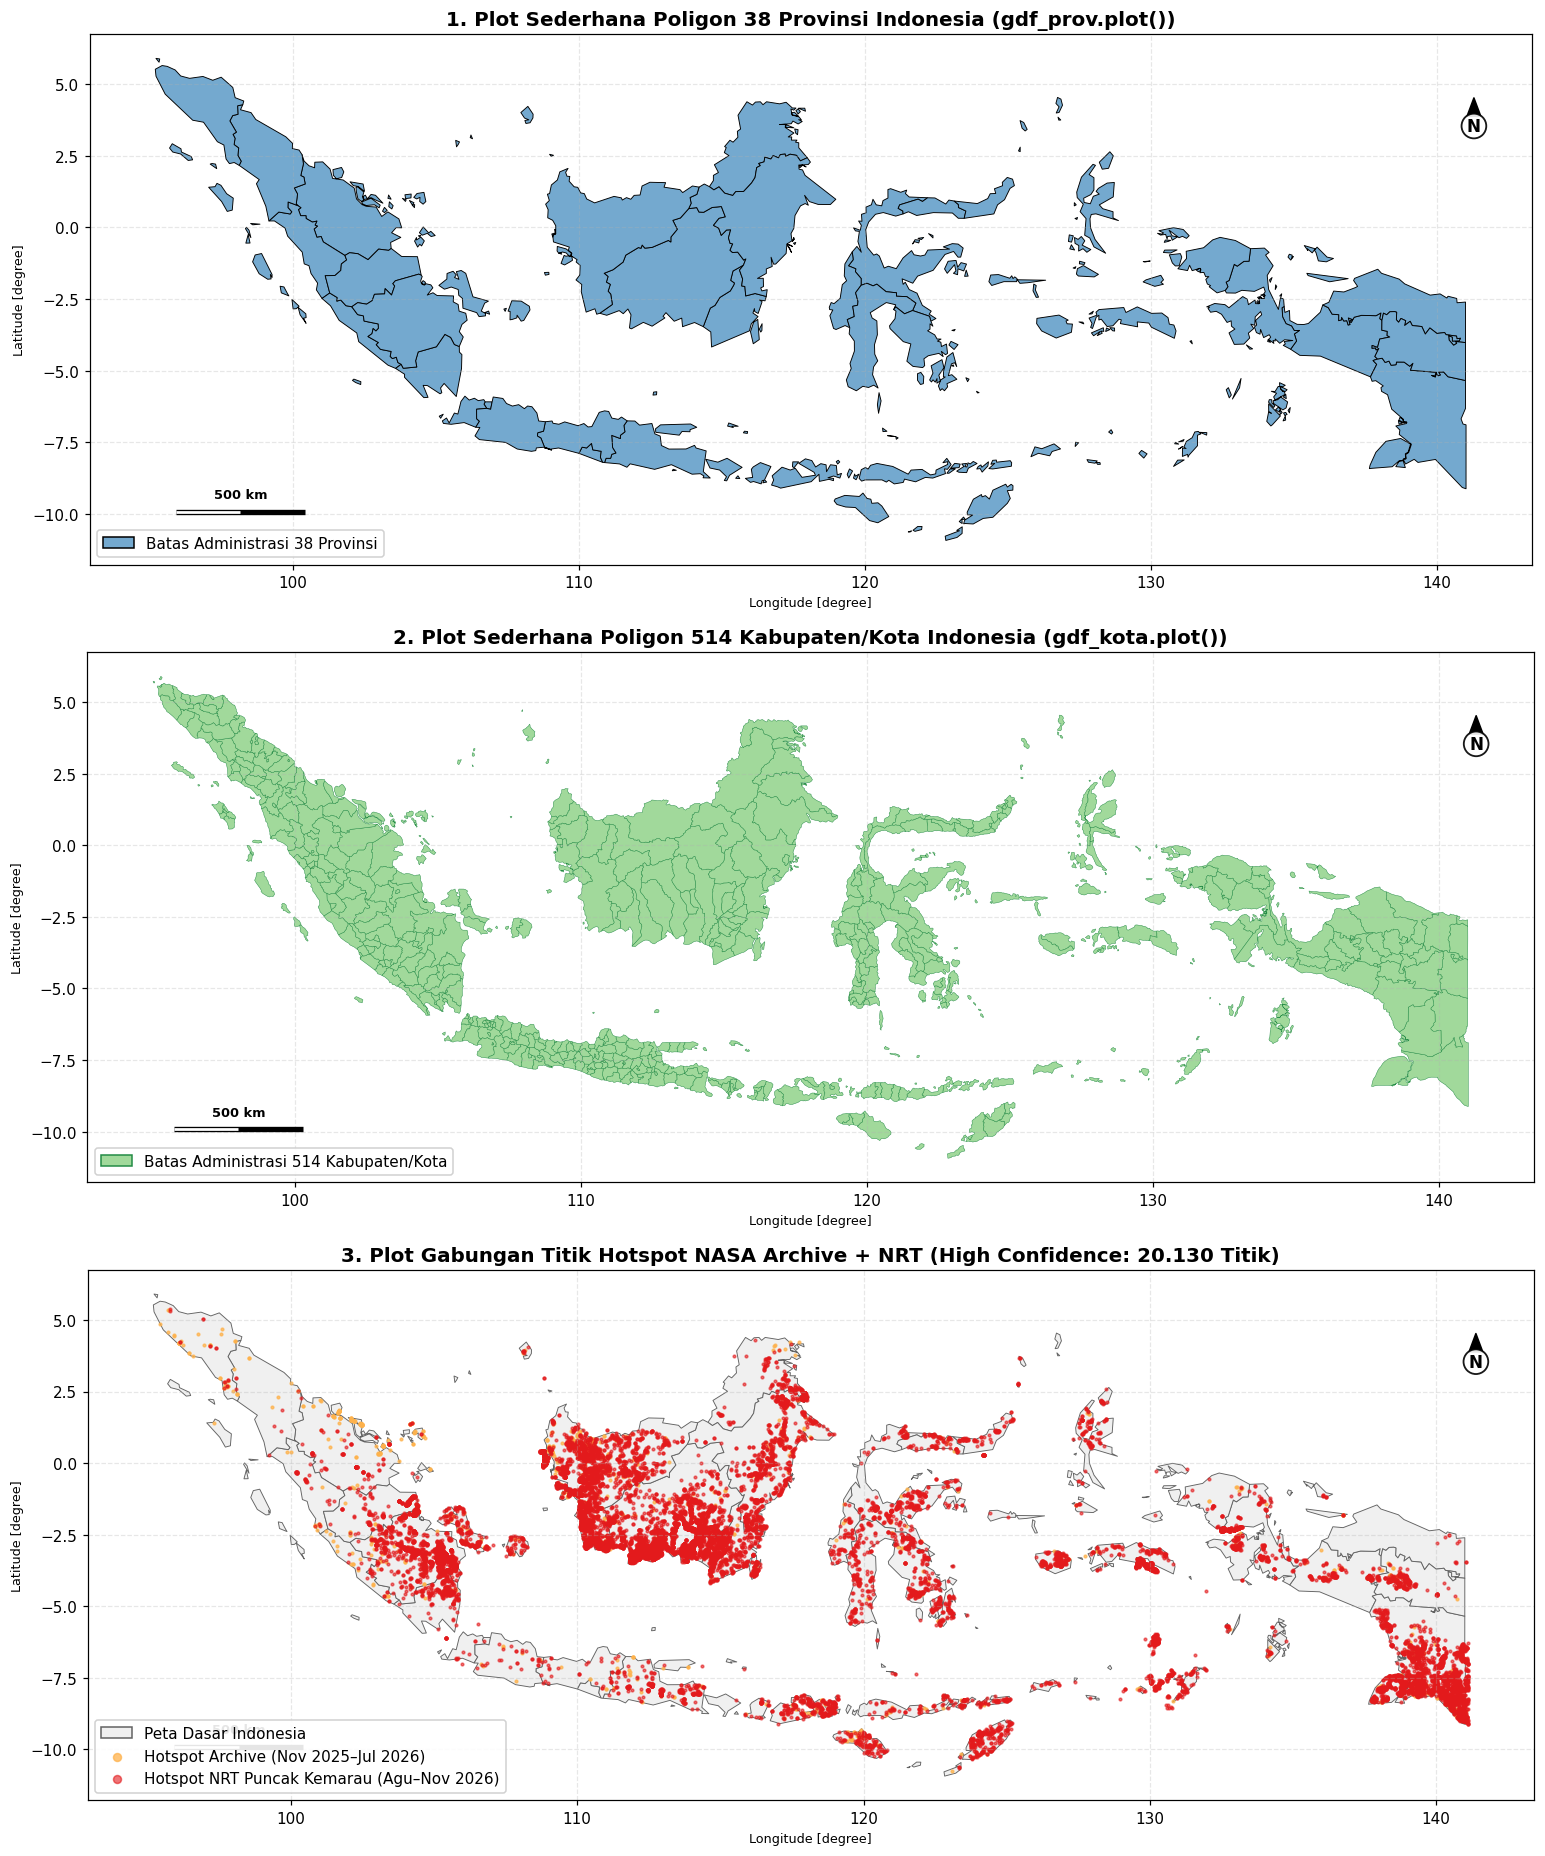

In [5]:
# 1D. Plot sederhana (.plot()) dilengkapi North Arrow, Scale Bar, Legenda, & Auto-Save
fig, axes = plt.subplots(3, 1, figsize=(15, 17))

# Plot 1: Poligon Provinsi
gdf_prov.plot(ax=axes[0], color="#74a9cf", edgecolor="black", linewidth=0.6)
patch_prov = mpatches.Patch(facecolor="#74a9cf", edgecolor="black", label="Batas Administrasi 38 Provinsi")
axes[0].legend(handles=[patch_prov], loc="lower left", framealpha=0.9)
tambah_north_arrow(axes[0], loc=(0.96, 0.88))
tambah_scale_bar(axes[0], panjang_km=500, loc=(0.06, 0.10))
axes[0].set_title("1. Plot Sederhana Poligon 38 Provinsi Indonesia (gdf_prov.plot())", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Longitude [degree]")
axes[0].set_ylabel("Latitude [degree]")
axes[0].grid(True, linestyle="--", alpha=0.3)

# Plot 2: Poligon Kabupaten/Kota
gdf_kota.plot(ax=axes[1], color="#a1d99b", edgecolor="#238b45", linewidth=0.3)
patch_kota = mpatches.Patch(facecolor="#a1d99b", edgecolor="#238b45", label="Batas Administrasi 514 Kabupaten/Kota")
axes[1].legend(handles=[patch_kota], loc="lower left", framealpha=0.9)
tambah_north_arrow(axes[1], loc=(0.96, 0.88))
tambah_scale_bar(axes[1], panjang_km=500, loc=(0.06, 0.10))
axes[1].set_title("2. Plot Sederhana Poligon 514 Kabupaten/Kota Indonesia (gdf_kota.plot())", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Longitude [degree]")
axes[1].set_ylabel("Latitude [degree]")
axes[1].grid(True, linestyle="--", alpha=0.3)

# Plot 3: Perbandingan Sebaran Titik Hotspot Archive vs NRT (High Confidence) di atas Peta Provinsi
gdf_prov.plot(ax=axes[2], color="#f0f0f0", edgecolor="#636363", linewidth=0.6)
gdf_hotspot[gdf_hotspot["sumber_data"].str.startswith("Archive")].plot(
    ax=axes[2], color="#feb24c", markersize=3.0, alpha=0.75, label="Hotspot Archive (Nov 2025–Jul 2026)"
)
gdf_hotspot[gdf_hotspot["sumber_data"].str.startswith("NRT")].plot(
    ax=axes[2], color="#e31a1c", markersize=3.0, alpha=0.60, label="Hotspot NRT Puncak Kemarau (Agu–Nov 2026)"
)
patch_bg = mpatches.Patch(facecolor="#f0f0f0", edgecolor="#636363", label="Peta Dasar Indonesia")
handles, labels = axes[2].get_legend_handles_labels()
axes[2].legend(handles=[patch_bg] + handles, loc="lower left", markerscale=3, framealpha=0.9)
tambah_north_arrow(axes[2], loc=(0.96, 0.88))
tambah_scale_bar(axes[2], panjang_km=500, loc=(0.06, 0.10))
axes[2].set_title("3. Plot Gabungan Titik Hotspot NASA Archive + NRT (High Confidence: 20.130 Titik)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Longitude [degree]")
axes[2].set_ylabel("Latitude [degree]")
axes[2].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
# Auto-Save Plot 1 ke folder output_maps/ dalam format PNG dan JPG
simpan_peta(fig, "tugas1_plot_sederhana_geojson_dan_hotspot")
plt.show()

---
## 2. Tugas 2: Menetapkan CRS (`set_crs(epsg=4326)`) dan Mengubah ke Proyeksi Metrik (`to_crs(epsg=3857)`)

> **Instruksi 2:** *Jika CRS belum ada, tetapkan dengan `set_crs(epsg=4326)` lalu ubah ke `EPSG:3857` dengan `to_crs`. Plot ulang.*

- **`EPSG:4326` (WGS 84)**: Sistem koordinat geografis menggunakan satuan **derajat lintang & bujur (`°`)**.
- **`EPSG:3857` (Pseudo-Mercator / Web Mercator)**: Sistem koordinat terproyeksi menggunakan satuan **meter (`m`)**, sehingga dapat digunakan untuk operasi jarak seperti `.buffer(500)` (500 meter).

In [6]:
# Periksa apakah CRS sudah ada; jika belum ada (None), tetapkan dengan set_crs(epsg=4326)
if gdf_prov.crs is None:
    gdf_prov = gdf_prov.set_crs(epsg=4326)

if gdf_kota.crs is None:
    gdf_kota = gdf_kota.set_crs(epsg=4326)

if gdf_hotspot.crs is None:
    print("gdf_hotspot belum memiliki CRS (None) -> menetapkan set_crs(epsg=4326)...")
    gdf_hotspot = gdf_hotspot.set_crs(epsg=4326)

print("CRS setelah set_crs(epsg=4326):")
print(" - gdf_prov   :", gdf_prov.crs)
print(" - gdf_kota   :", gdf_kota.crs)
print(" - gdf_hotspot:", gdf_hotspot.crs)

# Ubah dari EPSG:4326 (derajat) ke EPSG:3857 (meter) dengan to_crs(epsg=3857)
gdf_prov_3857 = gdf_prov.to_crs(epsg=3857)
gdf_kota_3857 = gdf_kota.to_crs(epsg=3857)
gdf_hotspot_3857 = gdf_hotspot.to_crs(epsg=3857)

print("\nCRS setelah to_crs(epsg=3857):")
print(" - gdf_prov_3857   :", gdf_prov_3857.crs)
print(" - gdf_kota_3857   :", gdf_kota_3857.crs)
print(" - gdf_hotspot_3857:", gdf_hotspot_3857.crs)

gdf_hotspot belum memiliki CRS (None) -> menetapkan set_crs(epsg=4326)...
CRS setelah set_crs(epsg=4326):
 - gdf_prov   : EPSG:4326
 - gdf_kota   : EPSG:4326
 - gdf_hotspot: EPSG:4326

CRS setelah to_crs(epsg=3857):
 - gdf_prov_3857   : EPSG:3857
 - gdf_kota_3857   : EPSG:3857
 - gdf_hotspot_3857: EPSG:3857


 [Auto-Save] Peta berhasil disimpan: output_maps\tugas2_perbandingan_crs_epsg4326_vs_epsg3857.png & output_maps\tugas2_perbandingan_crs_epsg4326_vs_epsg3857.jpg


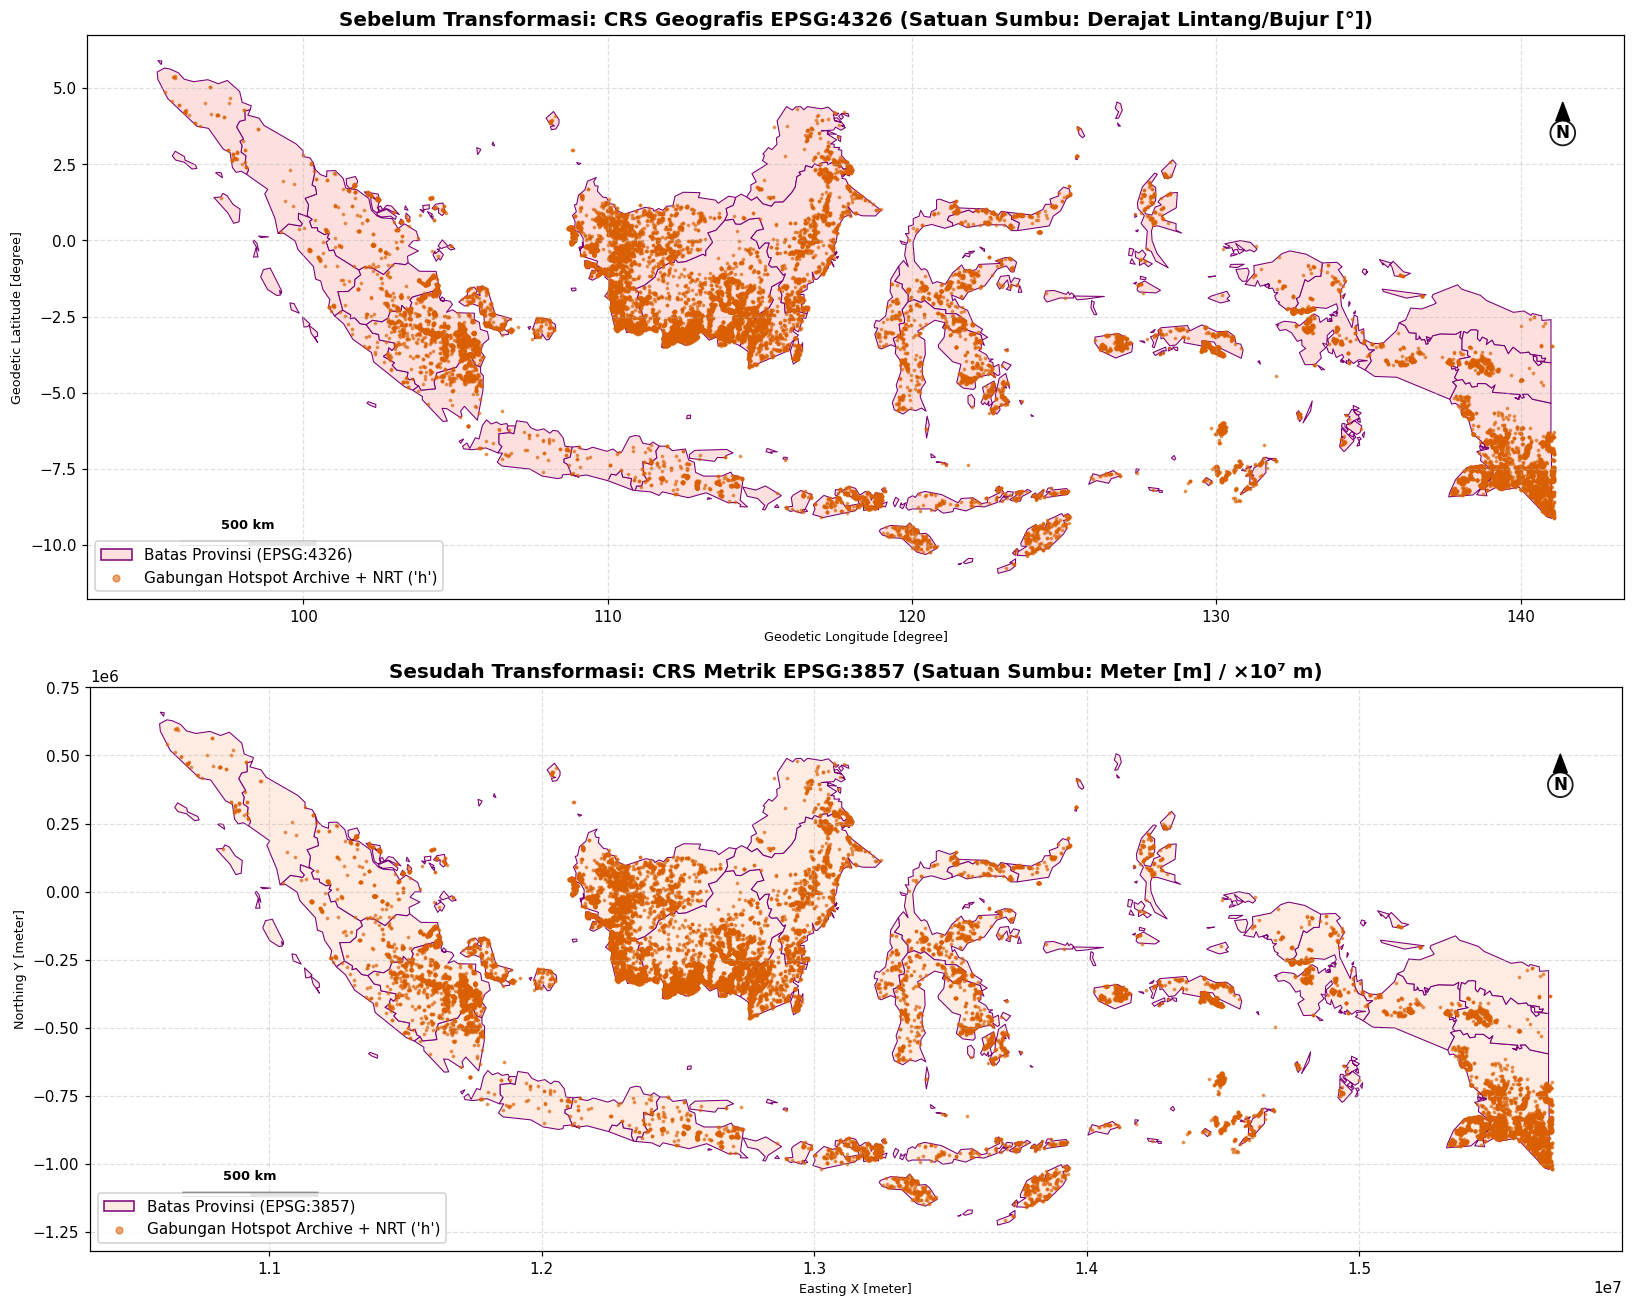

In [7]:
# Plot ulang perbandingan antara EPSG:4326 (Derajat) vs EPSG:3857 (Meter) lengkap dengan elemen kartografi
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# Plot EPSG:4326 (Geografis / Derajat)
gdf_prov.plot(ax=axes[0], color="#fde0dd", edgecolor="#7a0177", linewidth=0.7)
gdf_hotspot.plot(
    ax=axes[0], color="#d95f02", markersize=2.2, alpha=0.55, label="Gabungan Hotspot Archive + NRT ('h')"
)
patch_prov_geo = mpatches.Patch(facecolor="#fde0dd", edgecolor="#7a0177", label="Batas Provinsi (EPSG:4326)")
handles0, labels0 = axes[0].get_legend_handles_labels()
axes[0].legend(handles=[patch_prov_geo] + handles0, loc="lower left", markerscale=3, framealpha=0.9)
tambah_north_arrow(axes[0], loc=(0.96, 0.88))
tambah_scale_bar(axes[0], panjang_km=500, loc=(0.06, 0.10), is_metric=False)
axes[0].set_title("Sebelum Transformasi: CRS Geografis EPSG:4326 (Satuan Sumbu: Derajat Lintang/Bujur [°])", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Geodetic Longitude [degree]")
axes[0].set_ylabel("Geodetic Latitude [degree]")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Plot EPSG:3857 (Proyeksi Metrik / Meter)
gdf_prov_3857.plot(ax=axes[1], color="#feebe2", edgecolor="#7a0177", linewidth=0.7)
gdf_hotspot_3857.plot(
    ax=axes[1], color="#d95f02", markersize=2.2, alpha=0.55, label="Gabungan Hotspot Archive + NRT ('h')"
)
patch_prov_met = mpatches.Patch(facecolor="#feebe2", edgecolor="#7a0177", label="Batas Provinsi (EPSG:3857)")
handles1, labels1 = axes[1].get_legend_handles_labels()
axes[1].legend(handles=[patch_prov_met] + handles1, loc="lower left", markerscale=3, framealpha=0.9)
tambah_north_arrow(axes[1], loc=(0.96, 0.88))
tambah_scale_bar(axes[1], panjang_km=500, loc=(0.06, 0.10), is_metric=True)
axes[1].set_title("Sesudah Transformasi: CRS Metrik EPSG:3857 (Satuan Sumbu: Meter [m] / ×10⁷ m)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Easting X [meter]")
axes[1].set_ylabel("Northing Y [meter]")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
# Auto-Save Plot 2 ke folder output_maps/ dalam format PNG dan JPG
simpan_peta(fig, "tugas2_perbandingan_crs_epsg4326_vs_epsg3857")
plt.show()

---
## 3. Alur Khusus Provinsi Kalimantan Barat & Tugas 3: Buffer 500 Meter pada CRS Metrik (`EPSG:3857`)

> **Instruksi 3:** *Pada CRS metrik, buat buffer 500 pada titik/garis dan tampilkan plot perbandingan sebelum/sesudah.*

Mengacu pada contoh di `praktikum_geopandas1.ipynb` yang memfilter satu provinsi (`df.loc["JAWA BARAT"]`), di sini kita membuat **alur khusus untuk Provinsi Kalimantan Barat**:
1. Berdasarkan data `luas-karhutla-provinsi.xlsx`, pada tahun **2026** Kalimantan Barat menempati **peringkat ke-1 nasional** dengan luas kebakaran mencapai **38.310,86 Ha** (dan total akumulasi 2018–2026 mencapai **373.575,90 Ha**).
2. Dengan menggabungkan `archive` + `nrt`, jumlah titik panas *high confidence* di dalam batas administrasi Kalimantan Barat melonjak dari **336 titik (`archive` saja)** menjadi **7.515 titik (`archive` + `nrt`)** karena masuknya data puncak kemarau Agustus–Oktober 2026!

In [8]:
# 3A. Isolasi Data Provinsi Kalimantan Barat & Spatial Join dengan Gabungan Hotspot (Archive + NRT)
prov_indexed = gdf_prov.set_index("Provinsi")
kalbar_geom = prov_indexed.loc["Kalimantan Barat"]["geometry"]
kalbar_series = gpd.GeoSeries([kalbar_geom], crs=gdf_prov.crs)

# Filter 14 Kabupaten/Kota di Provinsi Kalimantan Barat (dalam EPSG:4326 dan EPSG:3857)
kalbar_kab = gdf_kota[gdf_kota["Provinsi"] == "Kalimantan Barat"].copy().sort_values(by="2026", ascending=False)
kalbar_kab_3857 = gdf_kota_3857[gdf_kota_3857["Provinsi"] == "Kalimantan Barat"].copy()

# Spatial Join: Ambil titik-titik hotspot (Archive + NRT) yang berada tepat di dalam Kabupaten/Kota Kalimantan Barat
kalbar_hotspots = gpd.sjoin(
    gdf_hotspot,
    kalbar_kab[['Kabupaten', 'geometry']],
    how="inner",
    predicate="within"
).copy()

kalbar_hotspots_3857 = kalbar_hotspots.to_crs(epsg=3857)

# Hitung jumlah titik hotspot Archive vs NRT per Kabupaten/Kota di Kalimantan Barat
rekap_hs_kab = (
    kalbar_hotspots.groupby(["Kabupaten", "sumber_data"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
rekap_hs_kab["Total_Hotspot_High"] = rekap_hs_kab.sum(axis=1, numeric_only=True)

kalbar_kab = kalbar_kab.merge(rekap_hs_kab, on="Kabupaten", how="left").fillna(0)

print(f"Total Luas Karhutla Kalimantan Barat Tahun 2026 : {prov_indexed.loc['Kalimantan Barat', '2026']:,.2f} Ha")
print(f"Total Luas Karhutla Kalbar Akumulasi 2018-2026  : {prov_indexed.loc['Kalimantan Barat', 'Total_2018_2026']:,.2f} Ha")
print(f"Hotspot High Confidence di Kalbar (Archive)     : {(kalbar_hotspots['sumber_data'].str.startswith('Archive')).sum():,} titik")
print(f"Hotspot High Confidence di Kalbar (NRT)         : {(kalbar_hotspots['sumber_data'].str.startswith('NRT')).sum():,} titik")
print(f"Total Gabungan Hotspot High Confidence Kalbar   : {len(kalbar_hotspots):,} titik")

# Tampilkan tabel perbandingan Luas Kebakaran (Ha) vs Jumlah Hotspot Archive & NRT di 14 Kabupaten/Kota Kalbar
kolom_tampil = [
    'Kode Wilayah', 'Kabupaten', '2024', '2025', '2026', 'Total_2018_2026',
    'Archive (Nov 2025 - Jul 2026)', 'NRT (Agu 2026 - Nov 2026)', 'Total_Hotspot_High'
]
kalbar_kab[kolom_tampil].reset_index(drop=True)

Total Luas Karhutla Kalimantan Barat Tahun 2026 : 38,310.86 Ha
Total Luas Karhutla Kalbar Akumulasi 2018-2026  : 445,936.01 Ha
Hotspot High Confidence di Kalbar (Archive)     : 290 titik
Hotspot High Confidence di Kalbar (NRT)         : 3,428 titik
Total Gabungan Hotspot High Confidence Kalbar   : 3,718 titik


,Kode Wilayah,Kabupaten,2024,2025,2026,Total_2018_2026,Archive (Nov 2025 - Jul 2026),NRT (Agu 2026 - Nov 2026),Total_Hotspot_High
0,6104.0,KETAPANG,2986.63,3948.85,12443.79,183481.18,71.0,1898.0,1969.0
1,6112.0,KUBU RAYA,2383.06,2548.38,8614.31,73636.06,25.0,270.0,295.0
2,6102.0,MEMPAWAH,882.67,2695.33,6144.98,18488.61,27.0,20.0,47.0
3,6111.0,KAYONG UTARA,547.83,499.38,4228.10,34081.56,21.0,157.0,178.0
4,6101.0,SAMBAS,2742.59,5004.03,2318.48,37926.81,4.0,16.0,20.0
5,6107.0,BENGKAYANG,1674.73,1090.62,1596.15,12483.41,12.0,28.0,40.0
6,6108.0,LANDAK,1732.80,964.09,853.68,13036.02,21.0,131.0,152.0
7,6103.0,SANGGAU,3286.68,2611.74,620.88,20613.78,56.0,297.0,353.0
8,6106.0,KAPUAS HULU,1210.74,1421.34,450.38,7887.43,12.0,147.0,159.0
9,6172.0,KOTA SINGKAWANG,42.15,248.14,377.76,2282.21,3.0,1.0,4.0


### 3B. Peta Sebaran Hotspot (`Archive` vs `NRT`) & Grafik Tren Bulanan (`Nov 2025 – Nov 2026`) serta Tahunan (`2018–2026`) di Kalimantan Barat

Berikut adalah visualisasi sebaran titik panas `Archive` (Nov 2025 – Jul 2026) vs `NRT` (Agu 2026 – Nov 2026) di Kalimantan Barat, dilengkapi **Grafik Tren Bulanan (`Nov 2025 – Nov 2026`)** yang menunjukkan lonjakan drastis titik panas pada bulan Agustus–September 2026.

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas3_peta_dan_tren_tahunan_kalimantan_barat.png & output_maps\tugas3_peta_dan_tren_tahunan_kalimantan_barat.jpg


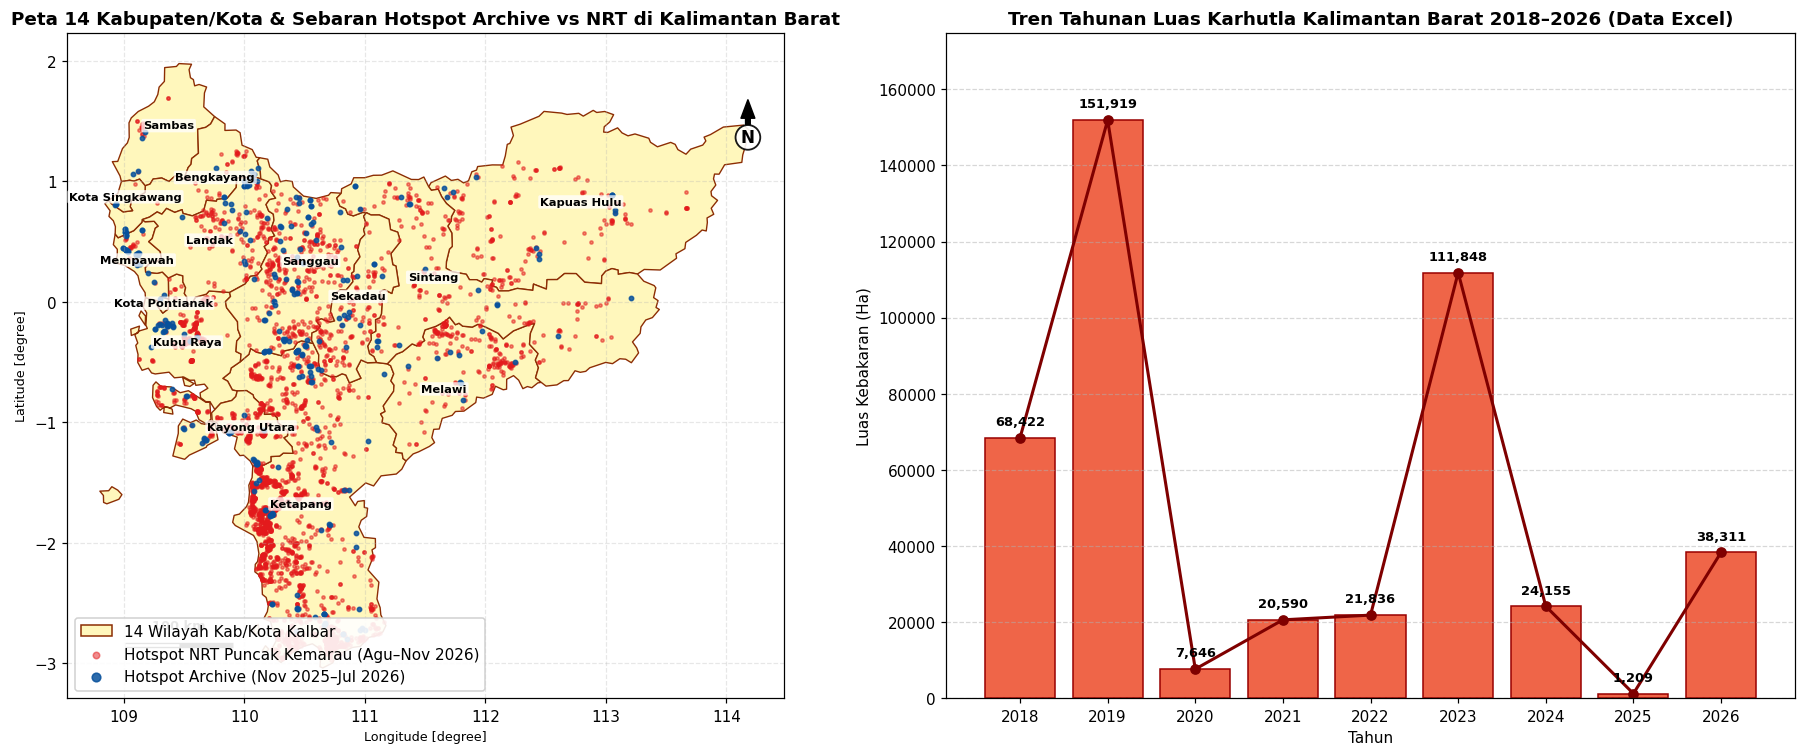

In [9]:
# Plot 1: Peta Sebaran Hotspot (Archive vs NRT) & Tren Tahunan Luas Kebakaran Kalimantan Barat (2018-2026)
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Kiri: Peta 14 Kabupaten/Kota Kalimantan Barat + Sebaran Hotspot Archive vs NRT
kalbar_kab.plot(ax=axes[0], color="#fff7bc", edgecolor="#8c2d04", linewidth=0.9)
kalbar_hotspots[kalbar_hotspots["sumber_data"].str.startswith("NRT")].plot(
    ax=axes[0], color="#e31a1c", markersize=4.5, alpha=0.50, label="Hotspot NRT Puncak Kemarau (Agu–Nov 2026)"
)
kalbar_hotspots[kalbar_hotspots["sumber_data"].str.startswith("Archive")].plot(
    ax=axes[0], color="#08519c", markersize=8.0, alpha=0.85, label="Hotspot Archive (Nov 2025–Jul 2026)"
)
patch_kalbar = mpatches.Patch(facecolor="#fff7bc", edgecolor="#8c2d04", label="14 Wilayah Kab/Kota Kalbar")
handles_k, labels_k = axes[0].get_legend_handles_labels()
axes[0].legend(handles=[patch_kalbar] + handles_k, loc="lower left", markerscale=2, framealpha=0.9)
tambah_north_arrow(axes[0], loc=(0.95, 0.90))
tambah_scale_bar(axes[0], panjang_km=100, loc=(0.08, 0.08), is_metric=False)

for _, row in kalbar_kab.iterrows():
    pt = row["geometry"].representative_point()
    axes[0].annotate(
        row["Kabupaten"].title(), xy=(pt.x, pt.y),
        ha="center", va="center", fontsize=7.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75)
    )
axes[0].set_title("Peta 14 Kabupaten/Kota & Sebaran Hotspot Archive vs NRT di Kalimantan Barat", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Longitude [degree]")
axes[0].set_ylabel("Latitude [degree]")
axes[0].grid(True, linestyle="--", alpha=0.3)

# Kanan: Tren Tahunan Luas Kebakaran Kalimantan Barat 2018-2026 (dari Excel)
nilai_tahunan_kalbar = [prov_indexed.loc["Kalimantan Barat", th] for th in TAHUN_LIST]
bars = axes[1].bar(TAHUN_LIST, nilai_tahunan_kalbar, color="#ef6548", edgecolor="#990000")
axes[1].plot(TAHUN_LIST, nilai_tahunan_kalbar, color="#7f0000", marker="o", linewidth=2)
for bar, val in zip(bars, nilai_tahunan_kalbar):
    axes[1].text(
        bar.get_x() + bar.get_width()/2, val + 2500,
        f"{val:,.0f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold"
    )
axes[1].set_ylim(0, max(nilai_tahunan_kalbar) * 1.15)
axes[1].set_title("Tren Tahunan Luas Karhutla Kalimantan Barat 2018–2026 (Data Excel)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Luas Kebakaran (Ha)")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas3_peta_dan_tren_tahunan_kalimantan_barat")
plt.show()

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas3_tren_bulanan_dan_komposisi_hotspot_kalbar.png & output_maps\tugas3_tren_bulanan_dan_komposisi_hotspot_kalbar.jpg


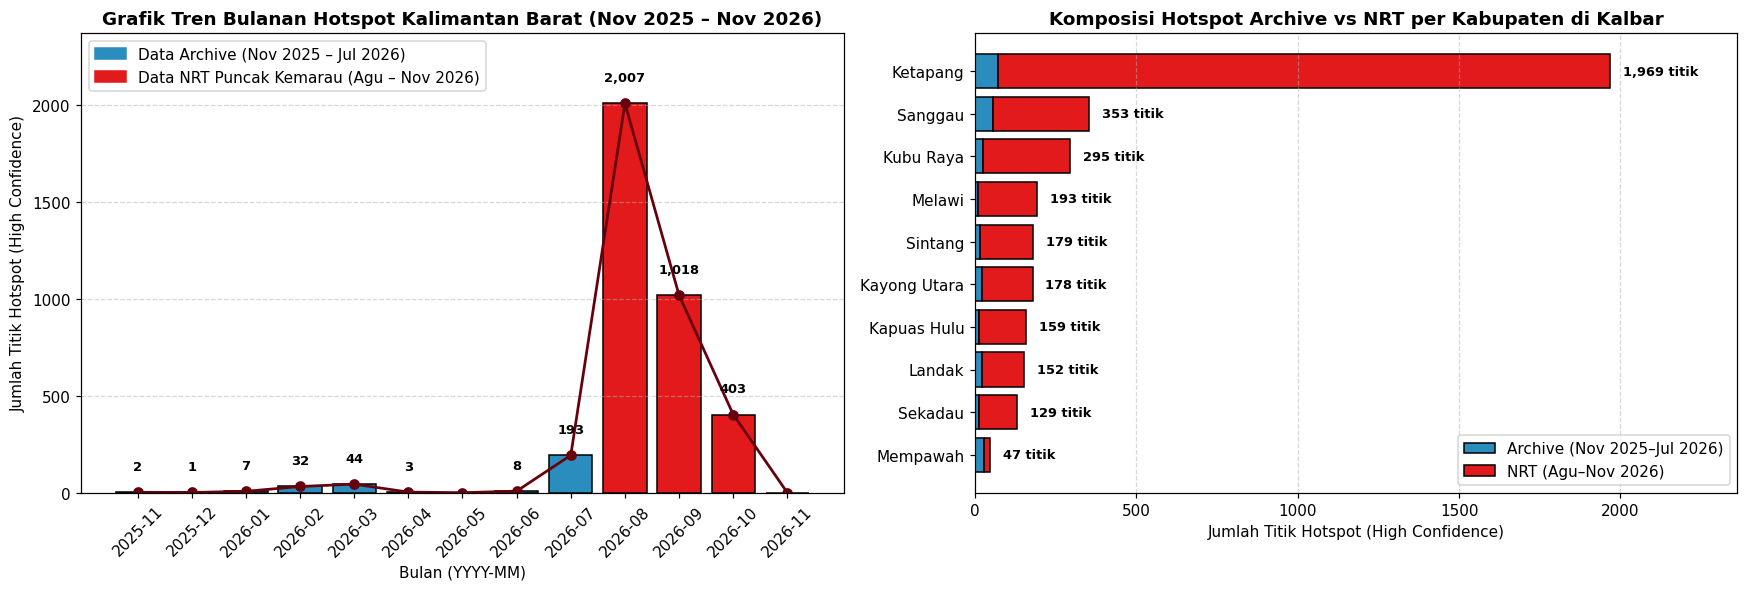

In [10]:
# Plot 2 (Khusus): Grafik Tren Bulanan Hotspot (Nov 2025 - Nov 2026) hasil penggabungan Archive + NRT di Kalimantan Barat
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel Kiri: Tren Bulanan Hotspot High Confidence di Kalimantan Barat
bulanan_kalbar = kalbar_hotspots.groupby("bulan").size()
semua_bulan = sorted(df_hotspot_all["bulan"].unique())
bulanan_kalbar = bulanan_kalbar.reindex(semua_bulan, fill_value=0)

warna_bulan = ["#2b8cbe" if b <= "2026-07" else "#e31a1c" for b in bulanan_kalbar.index]
bars_bln = axes[0].bar(bulanan_kalbar.index, bulanan_kalbar.values, color=warna_bulan, edgecolor="black")
axes[0].plot(bulanan_kalbar.index, bulanan_kalbar.values, color="#67000d", marker="o", linewidth=1.8)
for bar, val in zip(bars_bln, bulanan_kalbar.values):
    if val > 0:
        axes[0].text(bar.get_x() + bar.get_width()/2, val + 100, f"{val:,}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

patch_arc = mpatches.Patch(color="#2b8cbe", label="Data Archive (Nov 2025 – Jul 2026)")
patch_nrt = mpatches.Patch(color="#e31a1c", label="Data NRT Puncak Kemarau (Agu – Nov 2026)")
axes[0].legend(handles=[patch_arc, patch_nrt], loc="upper left")
axes[0].set_ylim(0, bulanan_kalbar.max() * 1.18)
axes[0].set_title("Grafik Tren Bulanan Hotspot Kalimantan Barat (Nov 2025 – Nov 2026)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Bulan (YYYY-MM)")
axes[0].set_ylabel("Jumlah Titik Hotspot (High Confidence)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Panel Kanan: Perbandingan Jumlah Hotspot Archive vs NRT pada 10 Kabupaten Tertinggi di Kalimantan Barat
top10_kab_hs = kalbar_kab.sort_values(by="Total_Hotspot_High", ascending=True).tail(10)
y_pos = np.arange(len(top10_kab_hs))
arc_vals = top10_kab_hs["Archive (Nov 2025 - Jul 2026)"].values
nrt_vals = top10_kab_hs["NRT (Agu 2026 - Nov 2026)"].values

axes[1].barh(y_pos, arc_vals, color="#2b8cbe", edgecolor="black", label="Archive (Nov 2025–Jul 2026)")
axes[1].barh(y_pos, nrt_vals, left=arc_vals, color="#e31a1c", edgecolor="black", label="NRT (Agu–Nov 2026)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top10_kab_hs["Kabupaten"].str.title())
for i, tot in enumerate(top10_kab_hs["Total_Hotspot_High"].values):
    axes[1].text(tot + 40, i, f"{int(tot):,} titik", va="center", fontsize=8.5, fontweight="bold")
axes[1].set_xlim(0, top10_kab_hs["Total_Hotspot_High"].max() * 1.2)
axes[1].set_title("Komposisi Hotspot Archive vs NRT per Kabupaten di Kalbar", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Titik Hotspot (High Confidence)")
axes[1].legend(loc="lower right")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas3_tren_bulanan_dan_komposisi_hotspot_kalbar")
plt.show()

### 3C. Pembuatan Buffer 500 Meter (`.buffer(500)`) pada Titik Hotspot dan Garis Batas di Kalimantan Barat (`EPSG:3857`)

Pada CRS metrik `EPSG:3857` (satuan meter), nilai `500` pada `.buffer(500)` merepresentasikan **radius 500 meter** (diameter 1 km).
- Dengan masuknya data `nrt`, kita dapat melihat **klaster titik panas yang saling berdekatan di Kabupaten Ketapang (Kalimantan Barat)** sehingga ketika diberikan `.buffer(500)`, zona dampak 500 meter antar-titik saling bersinggungan membentuk koridor area terbakar yang nyata.

In [11]:
# 1. Buat Buffer 500 meter pada Titik Hotspot Gabungan (Archive + NRT) di Kalimantan Barat (CRS Metrik EPSG:3857)
buffer_titik_500m = kalbar_hotspots_3857.copy()
buffer_titik_500m["geometry"] = kalbar_hotspots_3857.geometry.buffer(500)

# 2. Ekstrak Garis Batas (Boundary LineString) Kabupaten/Kota di Kalbar, lalu buat Buffer 500 meter
garis_batas_3857 = kalbar_kab_3857.copy()
garis_batas_3857["geometry"] = kalbar_kab_3857.geometry.boundary

buffer_garis_500m = garis_batas_3857.copy()
buffer_garis_500m["geometry"] = garis_batas_3857.geometry.buffer(500)

print("Tipe Geometry Titik Sebelum Buffer :", kalbar_hotspots_3857.geometry.geom_type.unique().tolist())
print("Tipe Geometry Titik Sesudah Buffer :", buffer_titik_500m.geometry.geom_type.unique().tolist())
print("Tipe Geometry Garis Sebelum Buffer :", garis_batas_3857.geometry.geom_type.unique().tolist())
print("Tipe Geometry Garis Sesudah Buffer :", buffer_garis_500m.geometry.geom_type.unique().tolist())

Tipe Geometry Titik Sebelum Buffer : ['Point']
Tipe Geometry Titik Sesudah Buffer : ['Polygon']
Tipe Geometry Garis Sebelum Buffer : ['LineString', 'MultiLineString']
Tipe Geometry Garis Sesudah Buffer : ['Polygon', 'MultiPolygon']


In [12]:
# Plot Perbandingan Sebelum vs Sesudah Buffer 500 Meter (Titik Hotspot & Garis Batas di Kalimantan Barat)
ketapang_pts = kalbar_hotspots_3857[kalbar_hotspots_3857["Kabupaten"] == "KETAPANG"]
center_pt = ketapang_pts.geometry.iloc[0]
zoom_radius = 4500  # 4,5 km ke kiri/kanan/atas/bawah agar klaster buffer 500 m tampak jelas

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# --- BARIS 1: BUFFER 500 METER PADA TITIK HOTSPOT ---
# Kiri Atas: Sebelum Buffer (Titik Point)
kalbar_kab_3857.plot(ax=axes[0, 0], color="#f7fcb9", edgecolor="#addd8e")
kalbar_hotspots_3857.plot(ax=axes[0, 0], color="#bd0026", markersize=28, label="Titik Hotspot Archive+NRT (Point)")
patch_bg_pt1 = mpatches.Patch(facecolor="#f7fcb9", edgecolor="#addd8e", label="Wilayah Kab. Ketapang")
handles_p1, labels_p1 = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(handles=[patch_bg_pt1] + handles_p1, loc="upper right", framealpha=0.9)
tambah_north_arrow(axes[0, 0], loc=(0.95, 0.88))
tambah_scale_bar(axes[0, 0], panjang_km=1, loc=(0.08, 0.08), is_metric=True)
axes[0, 0].set_xlim(center_pt.x - zoom_radius, center_pt.x + zoom_radius)
axes[0, 0].set_ylim(center_pt.y - zoom_radius, center_pt.y + zoom_radius)
axes[0, 0].set_title("SEBELUM Buffer: Klaster Titik Hotspot Ketapang (Point) - EPSG:3857", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("X [meter]")
axes[0, 0].set_ylabel("Y [meter]")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Kanan Atas: Sesudah Buffer 500m (Poligon Lingkaran Radius 500m + Titik Asli)
kalbar_kab_3857.plot(ax=axes[0, 1], color="#f7fcb9", edgecolor="#addd8e")
buffer_titik_500m.plot(ax=axes[0, 1], color="#fd8d3c", edgecolor="#bd0026", alpha=0.55, linewidth=1.2)
kalbar_hotspots_3857.plot(ax=axes[0, 1], color="#bd0026", markersize=14, label="Titik Pusat Hotspot")
patch_buf_pt = mpatches.Patch(facecolor="#fd8d3c", edgecolor="#bd0026", alpha=0.55, label="Zona Buffer 500 Meter (.buffer(500))")
patch_bg_pt2 = mpatches.Patch(facecolor="#f7fcb9", edgecolor="#addd8e", label="Wilayah Kab. Ketapang")
axes[0, 1].legend(handles=[patch_bg_pt2, patch_buf_pt, mpatches.Patch(color='#bd0026', label='Titik Pusat Hotspot')], loc="upper right", framealpha=0.9)
tambah_north_arrow(axes[0, 1], loc=(0.95, 0.88))
tambah_scale_bar(axes[0, 1], panjang_km=1, loc=(0.08, 0.08), is_metric=True)
axes[0, 1].set_xlim(center_pt.x - zoom_radius, center_pt.x + zoom_radius)
axes[0, 1].set_ylim(center_pt.y - zoom_radius, center_pt.y + zoom_radius)
axes[0, 1].set_title("SESUDAH Buffer 500m: Zona Dampak Kebakaran (.buffer(500))", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("X [meter]")
axes[0, 1].set_ylabel("Y [meter]")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# --- BARIS 2: BUFFER 500 METER PADA GARIS BATAS WILAYAH (BOUNDARY LINE) ---
ptk_geom = garis_batas_3857[garis_batas_3857["Kabupaten"] == "KOTA PONTIANAK"].geometry.iloc[0]
ptk_pt = ptk_geom.interpolate(0.5, normalized=True)
zoom_line = 4500

# Kiri Bawah: Sebelum Buffer (Garis Batas LineString)
garis_batas_3857.plot(ax=axes[1, 0], color="#08519c", linewidth=2.0, label="Garis Batas Wilayah (LineString)")
axes[1, 0].legend(loc="upper right", framealpha=0.9)
tambah_north_arrow(axes[1, 0], loc=(0.95, 0.88))
tambah_scale_bar(axes[1, 0], panjang_km=1, loc=(0.08, 0.08), is_metric=True)
axes[1, 0].set_xlim(ptk_pt.x - zoom_line, ptk_pt.x + zoom_line)
axes[1, 0].set_ylim(ptk_pt.y - zoom_line, ptk_pt.y + zoom_line)
axes[1, 0].set_title("SEBELUM Buffer: Garis Batas Pontianak–Kubu Raya (LineString)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("X [meter]")
axes[1, 0].set_ylabel("Y [meter]")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Kanan Bawah: Sesudah Buffer 500m pada Garis Batas
buffer_garis_500m.plot(ax=axes[1, 1], color="#6baed6", edgecolor="#08519c", alpha=0.55, linewidth=1.2)
garis_batas_3857.plot(ax=axes[1, 1], color="#08306b", linewidth=1.5, linestyle="--")
patch_buf_ln = mpatches.Patch(facecolor="#6baed6", edgecolor="#08519c", alpha=0.55, label="Koridor Buffer Garis 500m (.buffer(500))")
patch_line_ori = mpatches.Patch(color="#08306b", label="Garis Batas Asli (LineString)")
axes[1, 1].legend(handles=[patch_buf_ln, patch_line_ori], loc="upper right", framealpha=0.9)
tambah_north_arrow(axes[1, 1], loc=(0.95, 0.88))
tambah_scale_bar(axes[1, 1], panjang_km=1, loc=(0.08, 0.08), is_metric=True)
axes[1, 1].set_xlim(ptk_pt.x - zoom_line, ptk_pt.x + zoom_line)
axes[1, 1].set_ylim(ptk_pt.y - zoom_line, ptk_pt.y + zoom_line)
axes[1, 1].set_title("SESUDAH Buffer 500m: Koridor Sabuk Sekat Bakar Perbatasan (.buffer(500))", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("X [meter]")
axes[1, 1].set_ylabel("Y [meter]")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas3_perbandingan_buffer_500m_titik_dan_garis")
plt.show()

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas3_perbandingan_buffer_500m_titik_dan_garis.png & output_maps\tugas3_perbandingan_buffer_500m_titik_dan_garis.jpg


---
## 4. Tugas 4: Peta Choropleth Skema Sequential, Plot Semua Tahun (`2018`–`2026`), & Fitur Pilih Tahun/Provinsi

> **Instruksi 4:** *Buat choropleth sederhana dari satu kolom numerik dengan skema sequential. Jika tidak ada data, buat contoh kecil.*

Skema warna *sequential* (bergradasi satu arah dari terang ke gelap seperti `'YlOrRd'`, `'OrRd'`, atau `'Reds'`) sangat tepat digunakan untuk memetakan luas kebakaran hutan dan lahan (semakin pekat warna merahnya, semakin luas area yang terbakar).

Pada bagian ini kita menyajikan:
1. **4A. Peta Choropleth Sederhana Tingkat Provinsi & Kabupaten/Kota (Tahun 2026)** dengan skema *sequential* `YlOrRd`.
2. **4B. Peta Choropleth Khusus Provinsi Kalimantan Barat** (14 Kabupaten/Kota + *Overlay* Gabungan Titik Hotspot `archive` + `nrt`).
3. **4C. Peta Choropleth Komparasi Seluruh Tahun (`2018` s.d. `2026`)** baik tingkat Nasional maupun khusus **Kalimantan Barat**.
4. **4D. Fitur Interaktif Pilih Tahun dan Provinsi (`widgets.interact`)** untuk mengeksplorasi provinsi dan tahun mana pun secara fleksibel.

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas4_peta_choropleth_nasional_provinsi_dan_kota.png & output_maps\tugas4_peta_choropleth_nasional_provinsi_dan_kota.jpg


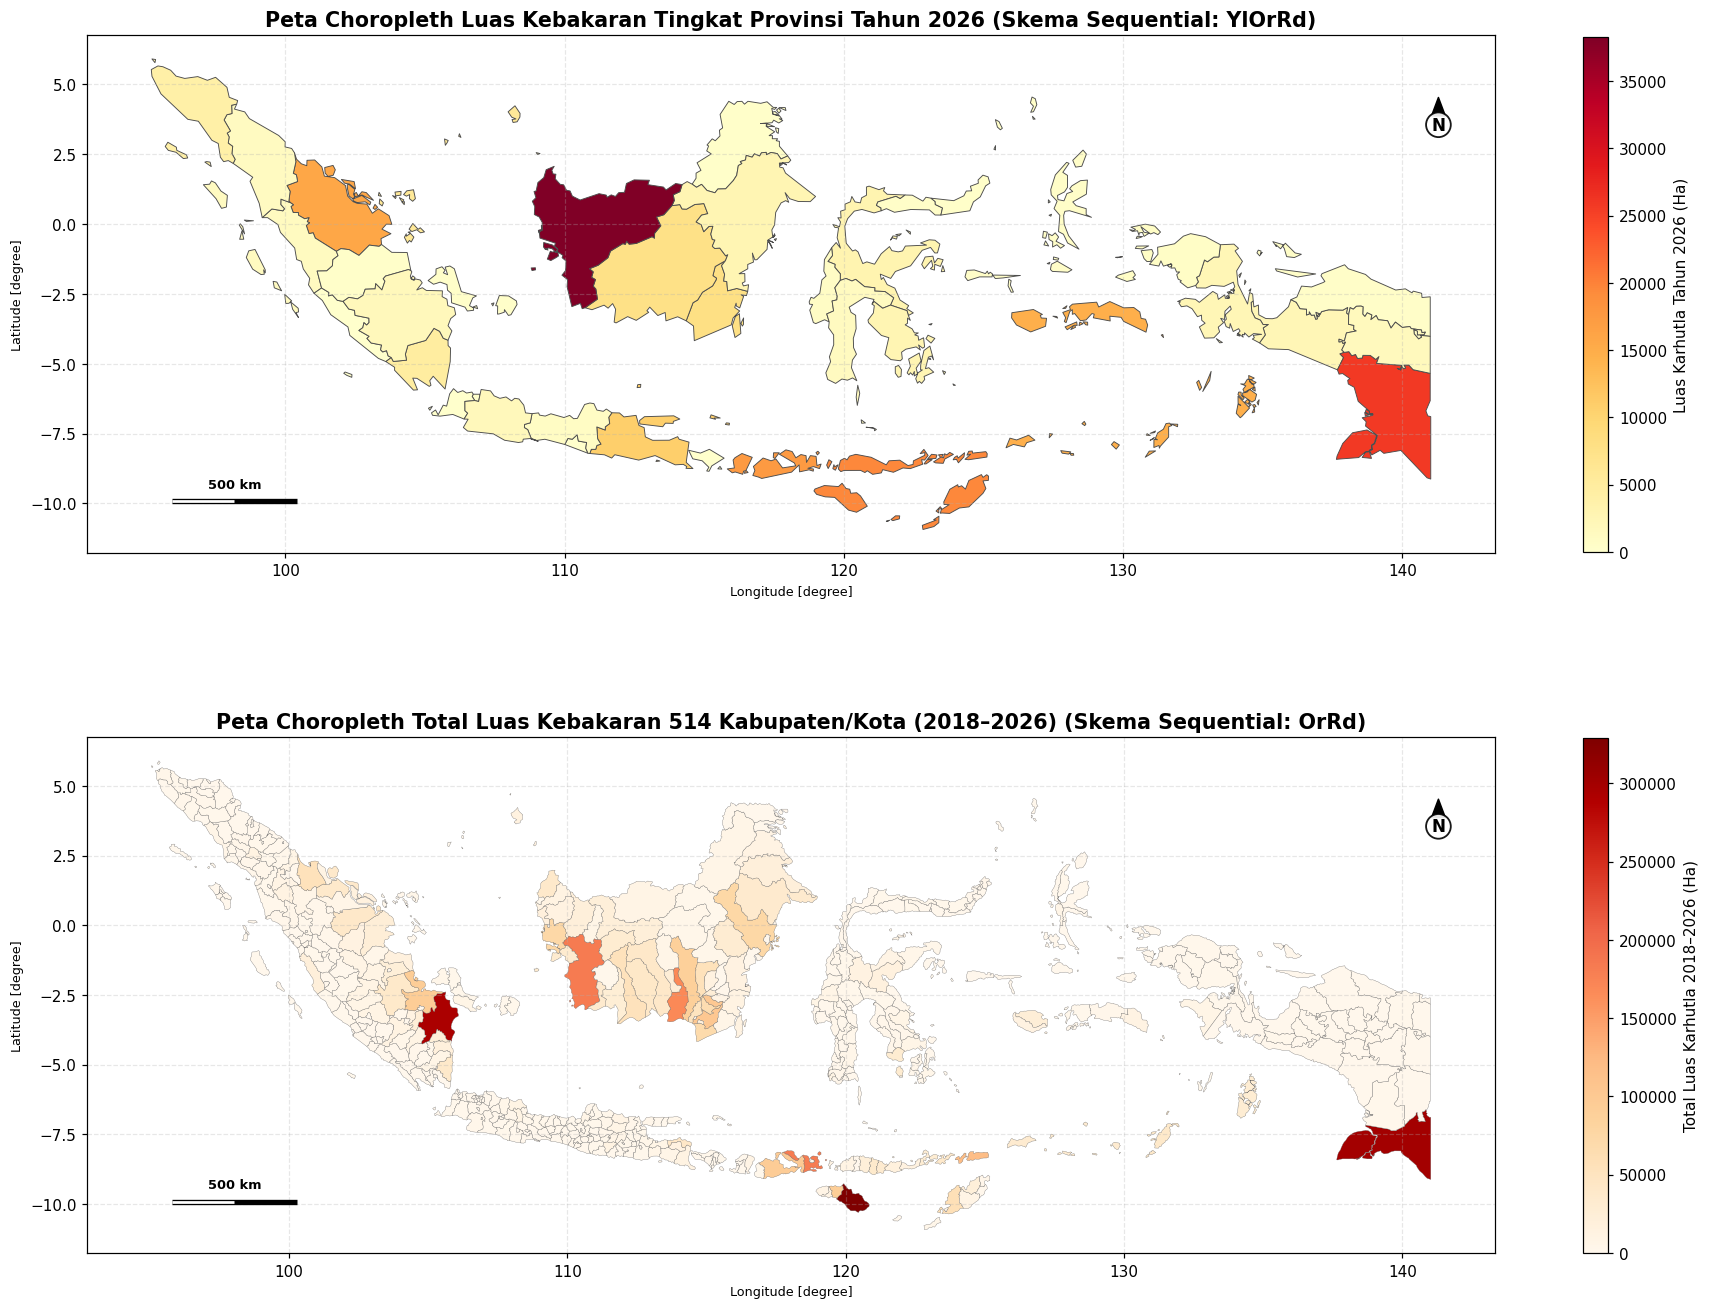

In [13]:
# 4A. Peta Choropleth Sederhana Skema Sequential ('YlOrRd' & 'OrRd') lengkap dengan elemen kartografi & Auto-Save
fig, axes = plt.subplots(2, 1, figsize=(17, 13))

# Choropleth 1: Tingkat Provinsi (Tahun 2026) dengan cmap sequential 'YlOrRd'
gdf_prov.plot(
    column="2026",
    ax=axes[0],
    legend=True,
    cmap="YlOrRd",
    edgecolor="#4d4d4d",
    linewidth=0.6,
    legend_kwds={"label": "Luas Karhutla Tahun 2026 (Ha)", "shrink": 0.75}
)
tambah_north_arrow(axes[0], loc=(0.96, 0.88))
tambah_scale_bar(axes[0], panjang_km=500, loc=(0.06, 0.10))
axes[0].set_title("Peta Choropleth Luas Kebakaran Tingkat Provinsi Tahun 2026 (Skema Sequential: YlOrRd)", fontsize=13.5, fontweight="bold")
axes[0].set_xlabel("Longitude [degree]")
axes[0].set_ylabel("Latitude [degree]")
axes[0].grid(True, linestyle="--", alpha=0.3)

# Choropleth 2: Tingkat Kabupaten/Kota (Akumulasi 2018-2026) dengan cmap sequential 'OrRd'
gdf_kota.plot(
    column="Total_2018_2026",
    ax=axes[1],
    legend=True,
    cmap="OrRd",
    edgecolor="#636363",
    linewidth=0.2,
    legend_kwds={"label": "Total Luas Karhutla 2018–2026 (Ha)", "shrink": 0.75}
)
tambah_north_arrow(axes[1], loc=(0.96, 0.88))
tambah_scale_bar(axes[1], panjang_km=500, loc=(0.06, 0.10))
axes[1].set_title("Peta Choropleth Total Luas Kebakaran 514 Kabupaten/Kota (2018–2026) (Skema Sequential: OrRd)", fontsize=13.5, fontweight="bold")
axes[1].set_xlabel("Longitude [degree]")
axes[1].set_ylabel("Latitude [degree]")
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas4_peta_choropleth_nasional_provinsi_dan_kota")
plt.show()

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas4_peta_choropleth_kalbar_dan_overlay_hotspot.png & output_maps\tugas4_peta_choropleth_kalbar_dan_overlay_hotspot.jpg


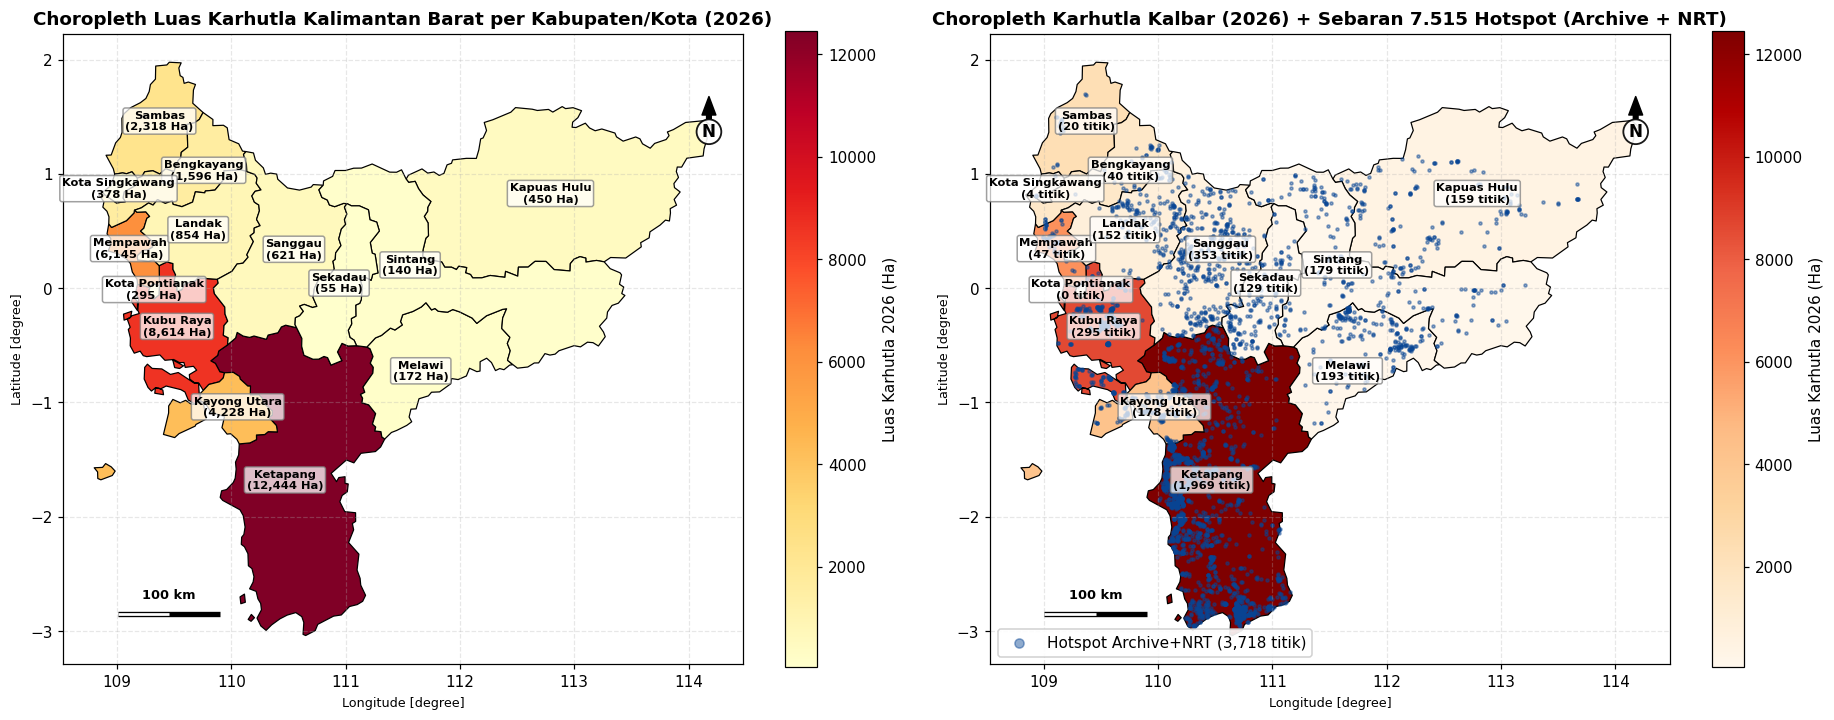

In [14]:
# 4B. Peta Choropleth Detail Khusus Provinsi Kalimantan Barat (Per Kabupaten/Kota Tahun 2026 + Overlay Hotspot Archive+NRT)
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# Kiri: Kalimantan Barat Tahun 2026
kalbar_kab.plot(
    column="2026",
    ax=axes[0],
    legend=True,
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.8,
    legend_kwds={"label": "Luas Karhutla 2026 (Ha)", "shrink": 0.75}
)
tambah_north_arrow(axes[0], loc=(0.95, 0.90))
tambah_scale_bar(axes[0], panjang_km=100, loc=(0.08, 0.08))

for _, row in kalbar_kab.iterrows():
    pt = row["geometry"].representative_point()
    axes[0].annotate(
        f"{row['Kabupaten'].title()}\n({row['2026']:,.0f} Ha)",
        xy=(pt.x, pt.y), ha="center", va="center", fontsize=7.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.75)
    )
axes[0].set_title("Choropleth Luas Karhutla Kalimantan Barat per Kabupaten/Kota (2026)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Longitude [degree]")
axes[0].set_ylabel("Latitude [degree]")
axes[0].grid(True, linestyle="--", alpha=0.3)

# Kanan: Kalimantan Barat Tahun 2026 + Overlay Gabungan Titik Hotspot (Archive + NRT)
kalbar_kab.plot(
    column="2026",
    ax=axes[1],
    legend=True,
    cmap="OrRd",
    edgecolor="black",
    linewidth=0.8,
    legend_kwds={"label": "Luas Karhutla 2026 (Ha)", "shrink": 0.75}
)
kalbar_hotspots.plot(
    ax=axes[1], color="#084594", markersize=4.0, alpha=0.45, label=f"Hotspot Archive+NRT ({len(kalbar_hotspots):,} titik)"
)
tambah_north_arrow(axes[1], loc=(0.95, 0.90))
tambah_scale_bar(axes[1], panjang_km=100, loc=(0.08, 0.08))

for _, row in kalbar_kab.iterrows():
    pt = row["geometry"].representative_point()
    axes[1].annotate(
        f"{row['Kabupaten'].title()}\n({int(row['Total_Hotspot_High']):,} titik)",
        xy=(pt.x, pt.y), ha="center", va="center", fontsize=7.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.75)
    )
axes[1].set_title("Choropleth Karhutla Kalbar (2026) + Sebaran 7.515 Hotspot (Archive + NRT)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Longitude [degree]")
axes[1].set_ylabel("Latitude [degree]")
axes[1].legend(loc="lower left", markerscale=3, framealpha=0.9)
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas4_peta_choropleth_kalbar_dan_overlay_hotspot")
plt.show()

### 4C. Visualisasi Peta Choropleth untuk Semua Tahun (`2018` s.d. `2026`)

Berikut adalah perbandingan spasiotemporal luas kebakaran hutan dan lahan untuk **kesembilan tahun (`2018`–`2026`)**:
1. **Tingkat Provinsi Seluruh Indonesia (`2018`–`2026`)**
2. **Tingkat Kabupaten/Kota Khusus Provinsi Kalimantan Barat (`2018`–`2026`)**

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas4_grid_semua_tahun_indonesia_2018_2026.png & output_maps\tugas4_grid_semua_tahun_indonesia_2018_2026.jpg


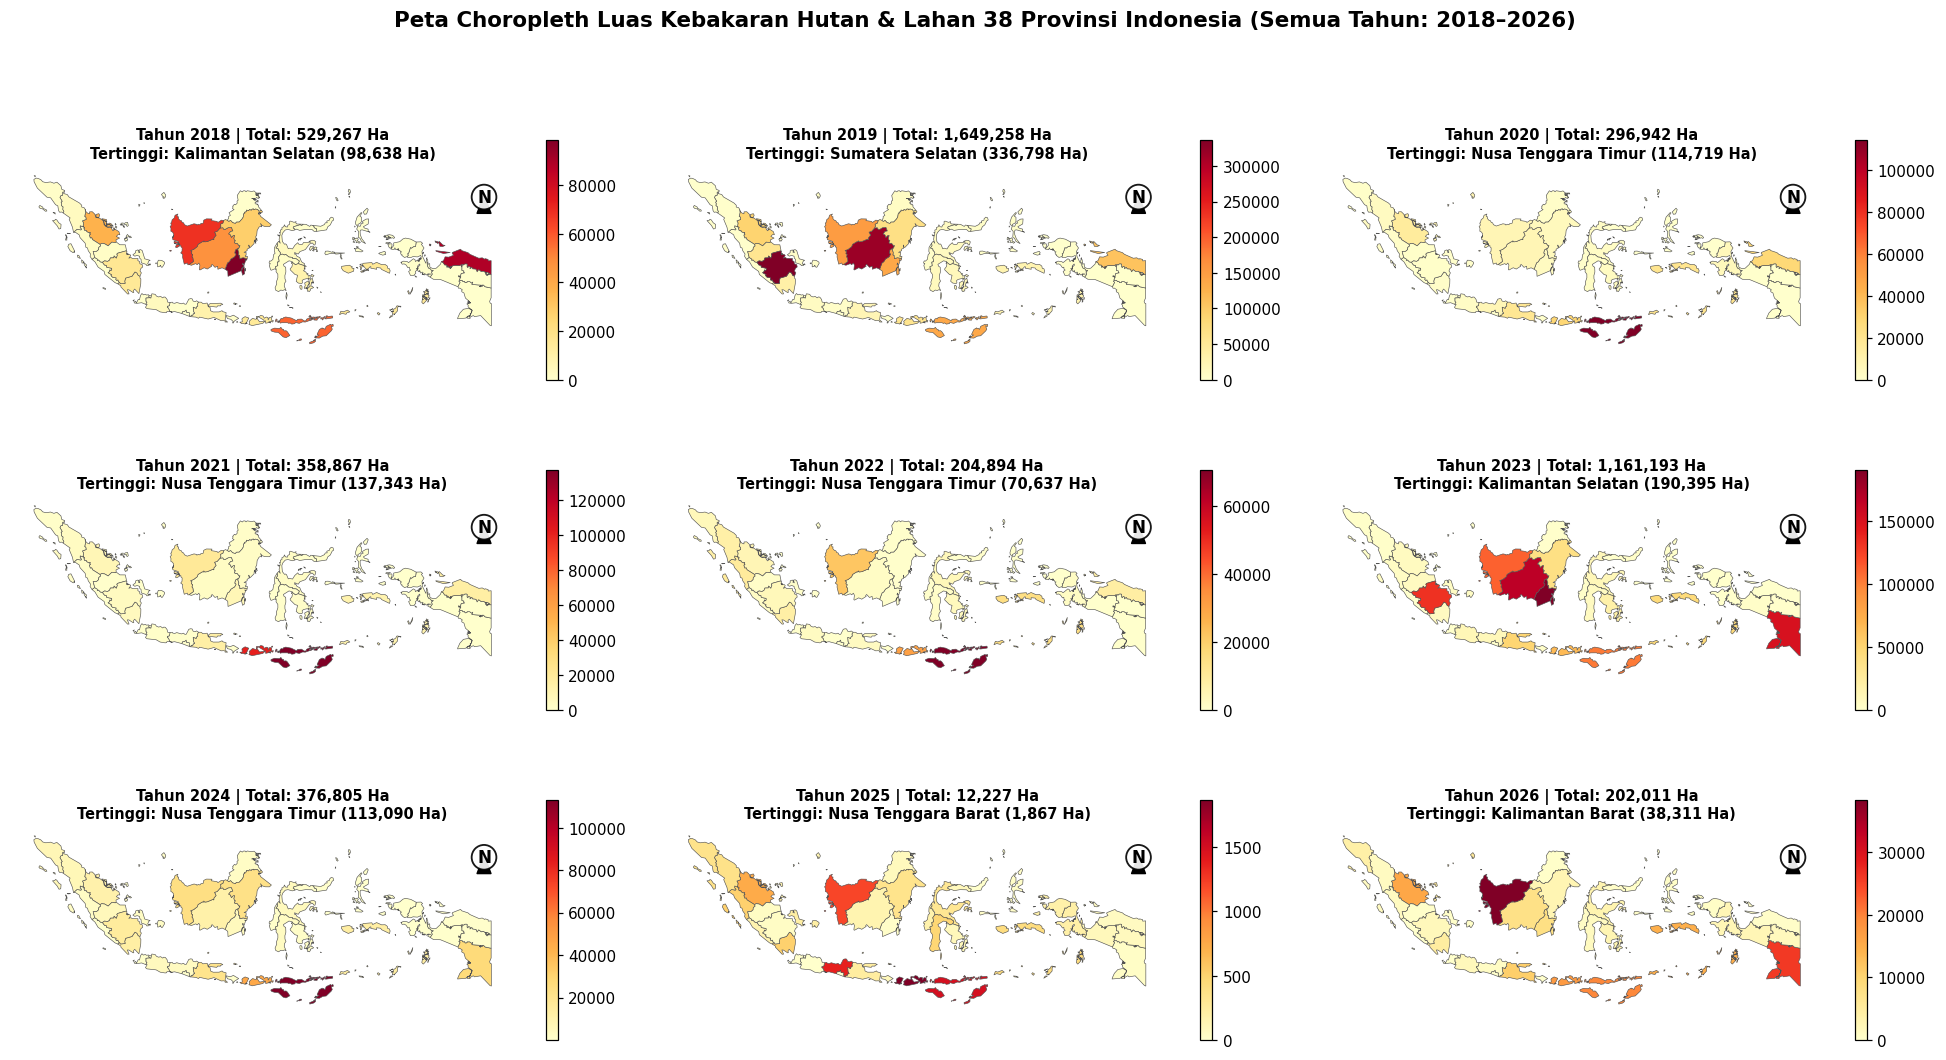

In [15]:
# Grid 3x3: Peta Choropleth Seluruh Provinsi di Indonesia untuk Semua Tahun (2018-2026)
fig, axes = plt.subplots(3, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, th in enumerate(TAHUN_LIST):
    ax = axes[idx]
    total_th = gdf_prov[th].sum()
    top_prov = gdf_prov.loc[gdf_prov[th].idxmax()]
    
    gdf_prov.plot(
        column=th,
        ax=ax,
        cmap="YlOrRd",
        edgecolor="#525252",
        linewidth=0.4,
        legend=True,
        legend_kwds={"shrink": 0.65}
    )
    tambah_north_arrow(ax, loc=(0.94, 0.85), size=0.06)
    ax.set_title(
        f"Tahun {th} | Total: {total_th:,.0f} Ha\nTertinggi: {top_prov['Provinsi']} ({top_prov[th]:,.0f} Ha)",
        fontsize=9.5, fontweight="bold"
    )
    ax.set_axis_off()

plt.suptitle("Peta Choropleth Luas Kebakaran Hutan & Lahan 38 Provinsi Indonesia (Semua Tahun: 2018–2026)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas4_grid_semua_tahun_indonesia_2018_2026")
plt.show()

 [Auto-Save] Peta berhasil disimpan: output_maps\tugas4_grid_semua_tahun_kalbar_2018_2026.png & output_maps\tugas4_grid_semua_tahun_kalbar_2018_2026.jpg


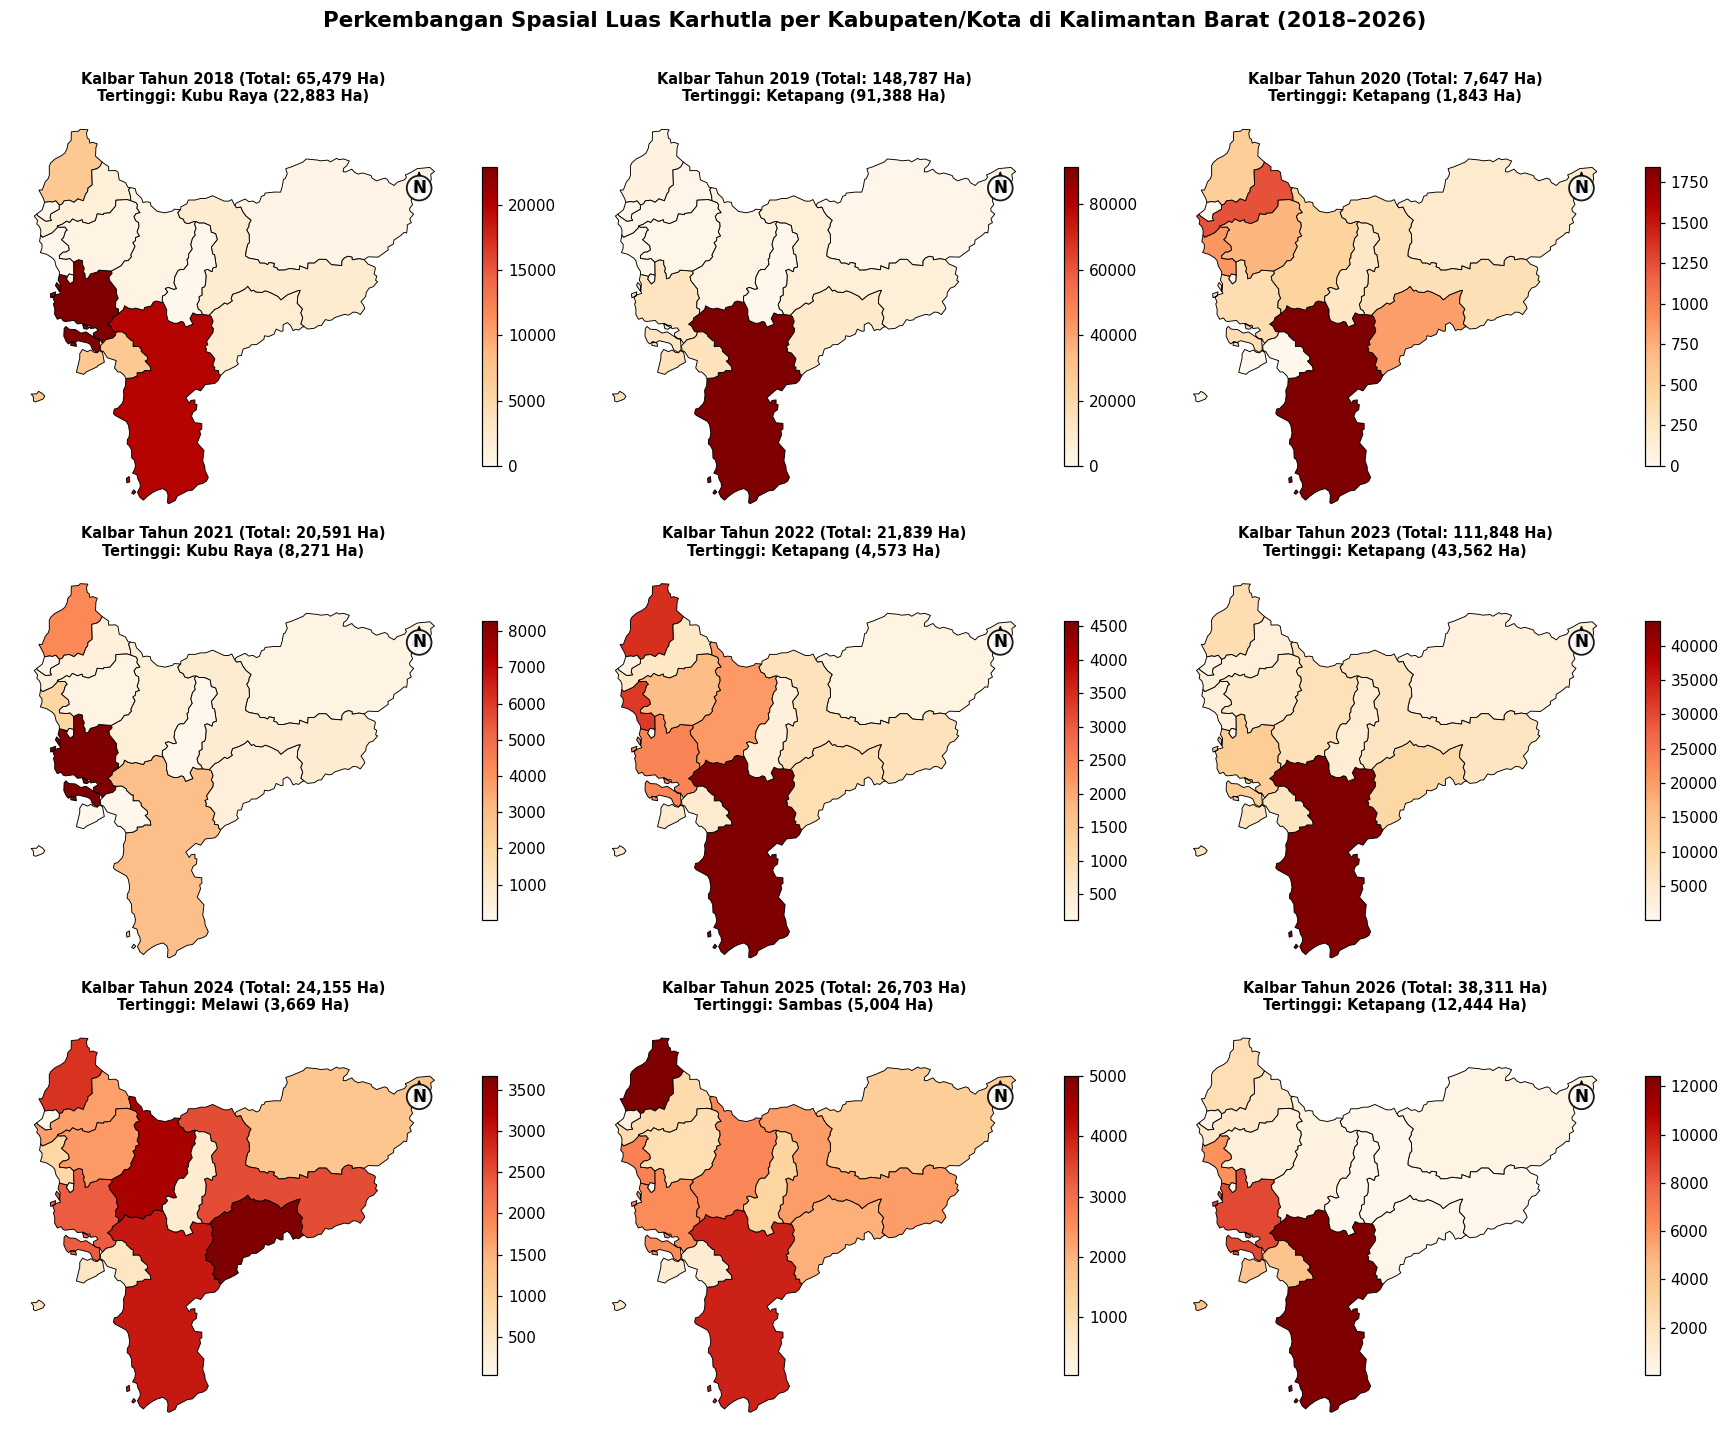

In [16]:
# Grid 3x3: Peta Choropleth Kabupaten/Kota di Kalimantan Barat untuk Semua Tahun (2018-2026)
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for idx, th in enumerate(TAHUN_LIST):
    ax = axes[idx]
    total_kalbar_th = kalbar_kab[th].sum()
    top_kab = kalbar_kab.loc[kalbar_kab[th].idxmax()]
    
    kalbar_kab.plot(
        column=th,
        ax=ax,
        cmap="OrRd",
        edgecolor="black",
        linewidth=0.6,
        legend=True,
        legend_kwds={"shrink": 0.7}
    )
    tambah_north_arrow(ax, loc=(0.92, 0.85), size=0.06)
    ax.set_title(
        f"Kalbar Tahun {th} (Total: {total_kalbar_th:,.0f} Ha)\nTertinggi: {top_kab['Kabupaten'].title()} ({top_kab[th]:,.0f} Ha)",
        fontsize=9.5, fontweight="bold"
    )
    ax.set_axis_off()

plt.suptitle("Perkembangan Spasial Luas Karhutla per Kabupaten/Kota di Kalimantan Barat (2018–2026)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
# Auto-Save ke folder output_maps/
simpan_peta(fig, "tugas4_grid_semua_tahun_kalbar_2018_2026")
plt.show()

---
### 4D. Fitur Pemilih Interaktif (Dropdown Selector `widgets.interact`) Tahun dan Provinsi

Gunakan **Dropdown Selector Interaktif (`widgets.interact`)** di bawah ini untuk memilih secara bebas:
- **`Pilih Tahun`**: `'2018'`, `'2019'`, `'2020'`, `'2021'`, `'2022'`, `'2023'`, `'2024'`, `'2025'`, `'2026'`, `'Total_2018_2026'`, atau `'Rata_Rata_Tahunan'`.
- **`Pilih Provinsi`**: Pilih `'Semua Provinsi (Nasional)'` untuk melihat peta seluruh Indonesia, atau pilih salah satu dari **38 Provinsi** (misalnya `'Kalimantan Barat'`, `'Riau'`, `'Kalimantan Tengah'`, `'Papua Selatan'`, `'Jawa Timur'`, dll.) untuk melihat peta *choropleth* tingkat **Kabupaten/Kota** beserta sebaran titik hotspot gabungan (`Archive + NRT`).
- **`Auto-Save Peta Terpilih`**: Setiap pilihan peta yang dihasilkan dapat langsung disimpan secara otomatis ke folder `output_maps/`.

 [Auto-Save] Peta berhasil disimpan: output_maps\peta_karhutla_kalimantan_barat_2026.png & output_maps\peta_karhutla_kalimantan_barat_2026.jpg
interactive(children=(Dropdown(description='Pilih Tahun:', index=8, options=('2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', 'Total_2018_2026', 'Rata_Rata_Tahunan'), value='2026'), Dropdown(description='Pilih Provinsi:', index=12, options=('Semua Provinsi (Nasional)', 'Aceh', 'Bali', 'Bangka Belitung', 'Banten', 'Bengkulu', 'DKI Jakarta', 'Gorontalo', 'Jambi', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Kalimantan Barat', 'Kalimantan Selatan', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara', 'Kepulauan Riau', 'Lampung', 'Maluku', 'Maluku Utara', 'Nusa Tenggara Barat', 'Nusa Tenggara Timur', 'Papua', 'Papua Barat', 'Papua Barat Daya', 'Papua Pegunungan', 'Papua Selatan', 'Papua Tengah', 'Riau', 'Sulawesi Barat', 'Sulawesi Selatan', 'Sulawesi Tengah', 'Sulawesi Tenggara', 'Sulawesi Utara', 'Sumatera Barat', 'Sum

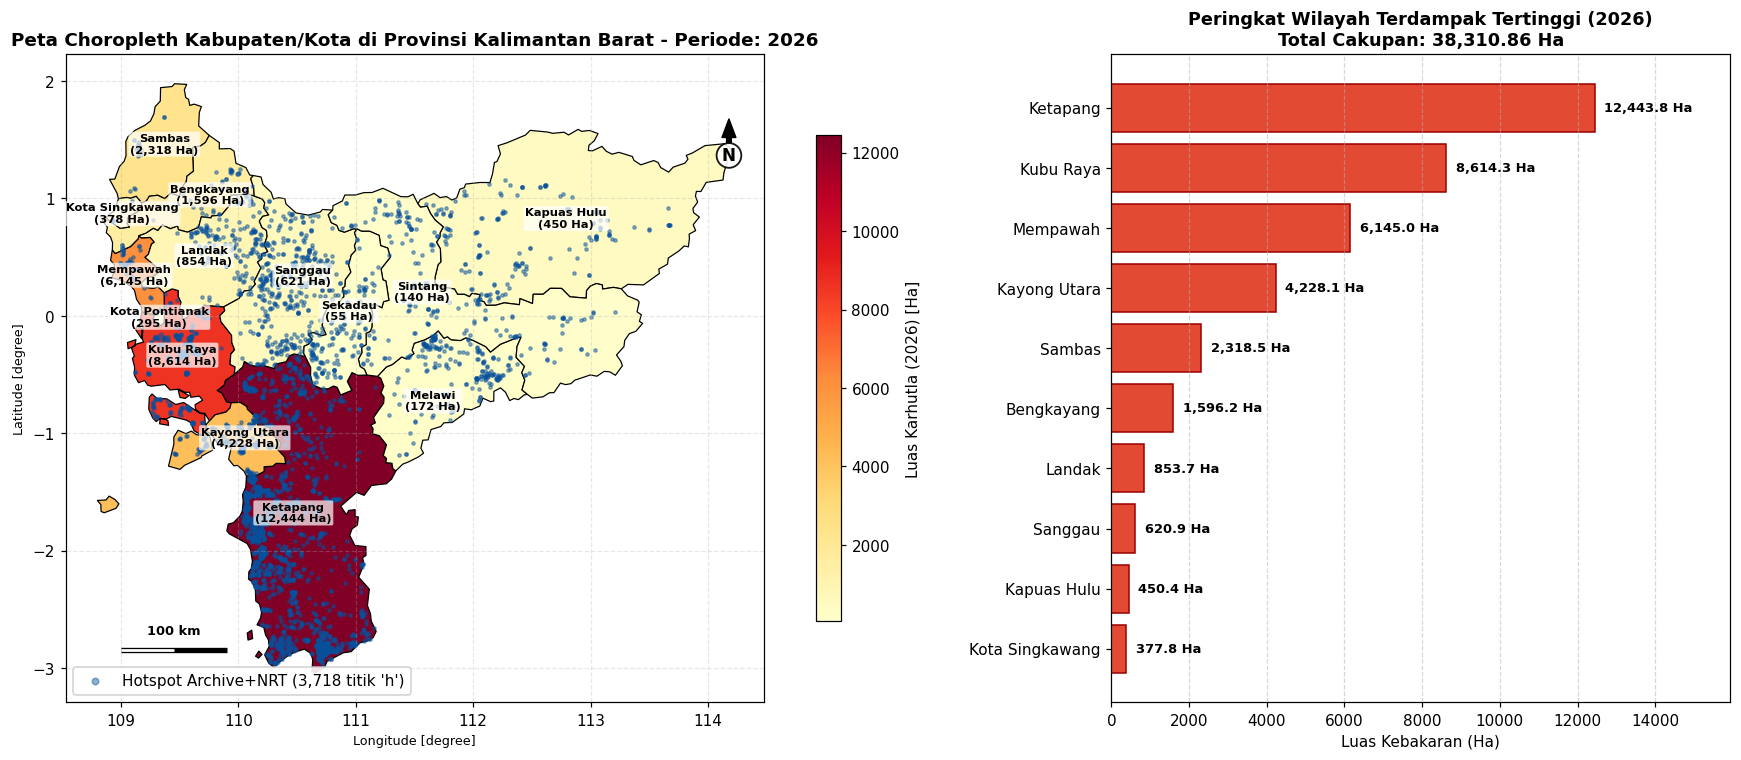

In [17]:
import ipywidgets as widgets
from IPython.display import display

DAFTAR_PROVINSI = ["Semua Provinsi (Nasional)"] + sorted(gdf_prov["Provinsi"].unique().tolist())
DAFTAR_KOLOM_TAHUN = TAHUN_LIST + ["Total_2018_2026", "Rata_Rata_Tahunan"]

def tampilkan_peta_karhutla(
    tahun="2026",
    provinsi="Kalimantan Barat",
    cmap="YlOrRd",
    tampilkan_hotspot=True,
    auto_save=True
):
    """
    Fungsi untuk mem-plot Peta Choropleth Karhutla berdasarkan pilihan Tahun dan Provinsi.
    Lengkap dengan North Arrow, Scale Bar, Legenda, dan opsi Auto-Save (PNG/JPG).
    """
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.7, 1]})
    
    if provinsi == "Semua Provinsi (Nasional)":
        sub_gdf = gdf_prov.copy().sort_values(by=tahun, ascending=False)
        kolom_wilayah = "Provinsi"
        judul_peta = f"Peta Choropleth Karhutla Nasional (38 Provinsi) - Periode: {tahun}"
        
        sub_gdf.plot(
            column=tahun, ax=axes[0], cmap=cmap, edgecolor="#444444", linewidth=0.6,
            legend=True, legend_kwds={"label": f"Luas Karhutla ({tahun}) [Ha]", "shrink": 0.75}
        )
        tambah_north_arrow(axes[0], loc=(0.95, 0.88))
        tambah_scale_bar(axes[0], panjang_km=500, loc=(0.06, 0.10))
        
        if tampilkan_hotspot:
            gdf_hotspot.plot(
                ax=axes[0], color="#08519c", markersize=2.5, alpha=0.45, label="Hotspot NASA Archive+NRT ('h')"
            )
            axes[0].legend(loc="lower left", markerscale=3, framealpha=0.9)
    else:
        sub_gdf = gdf_kota[gdf_kota["Provinsi"] == provinsi].copy().sort_values(by=tahun, ascending=False)
        kolom_wilayah = "Kabupaten"
        judul_peta = f"Peta Choropleth Kabupaten/Kota di Provinsi {provinsi} - Periode: {tahun}"
        
        sub_gdf.plot(
            column=tahun, ax=axes[0], cmap=cmap, edgecolor="black", linewidth=0.8,
            legend=True, legend_kwds={"label": f"Luas Karhutla ({tahun}) [Ha]", "shrink": 0.75}
        )
        tambah_north_arrow(axes[0], loc=(0.95, 0.90))
        tambah_scale_bar(axes[0], panjang_km=100, loc=(0.08, 0.08))
        
        for _, row in sub_gdf.iterrows():
            pt = row["geometry"].representative_point()
            axes[0].annotate(
                f"{row['Kabupaten'].title()}\n({row[tahun]:,.0f} Ha)",
                xy=(pt.x, pt.y), ha="center", va="center", fontsize=7.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7)
            )
        if tampilkan_hotspot:
            minx, miny, maxx, maxy = sub_gdf.total_bounds
            hs_sub = gdf_hotspot.cx[minx:maxx, miny:maxy]
            hs_in_prov = gpd.sjoin(hs_sub, sub_gdf[["geometry"]], how="inner", predicate="within")
            if len(hs_in_prov) > 0:
                hs_in_prov.plot(
                    ax=axes[0], color="#08519c", markersize=4.5, alpha=0.45, label=f"Hotspot Archive+NRT ({len(hs_in_prov):,} titik 'h')"
                )
                axes[0].legend(loc="lower left", markerscale=2, framealpha=0.9)

    axes[0].set_title(judul_peta, fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Longitude [degree]")
    axes[0].set_ylabel("Latitude [degree]")
    axes[0].grid(True, linestyle="--", alpha=0.3)

    # Panel Kanan: Top 10 Wilayah Tertinggi pada Tahun & Cakupan Terpilih
    top_df = sub_gdf.head(10).iloc[::-1]
    bars = axes[1].barh(top_df[kolom_wilayah].str.title(), top_df[tahun], color="#e34a33", edgecolor="#990000")
    max_val = max(top_df[tahun].max(), 1.0)
    for bar, val in zip(bars, top_df[tahun]):
        axes[1].text(val + max_val * 0.02, bar.get_y() + bar.get_height()/2, f"{val:,.1f} Ha", va="center", fontsize=8.5, fontweight="bold")
    axes[1].set_xlim(0, max_val * 1.28)
    axes[1].set_title(f"Peringkat Wilayah Terdampak Tertinggi ({tahun})\nTotal Cakupan: {sub_gdf[tahun].sum():,.2f} Ha", fontsize=11.5, fontweight="bold")
    axes[1].set_xlabel("Luas Kebakaran (Ha)")
    axes[1].grid(axis="x", linestyle="--", alpha=0.5)

    plt.tight_layout()
    
    if auto_save:
        nama_bersih = f"peta_karhutla_{provinsi.lower().replace(' ', '_').replace('(', '').replace(')', '')}_{tahun}"
        simpan_peta(fig, nama_bersih)
        
    plt.show()

# Fitur Dropdown Selector Interaktif (Pilih Tahun, Provinsi, Skema Warna, dan Overlay Hotspot)
selector_interaktif = widgets.interact(
    tampilkan_peta_karhutla,
    tahun=widgets.Dropdown(options=DAFTAR_KOLOM_TAHUN, value="2026", description="Pilih Tahun:"),
    provinsi=widgets.Dropdown(options=DAFTAR_PROVINSI, value="Kalimantan Barat", description="Pilih Provinsi:"),
    cmap=widgets.Dropdown(options=["YlOrRd", "OrRd", "Reds", "YlOrBr", "inferno_r"], value="YlOrRd", description="Skema Warna:"),
    tampilkan_hotspot=widgets.Checkbox(value=True, description="Tampilkan Titik Hotspot NASA"),
    auto_save=widgets.Checkbox(value=True, description="Auto-Save Peta (PNG)")
)

 [Auto-Save] Peta berhasil disimpan: output_maps\peta_karhutla_kalimantan_tengah_2026.png & output_maps\peta_karhutla_kalimantan_tengah_2026.jpg


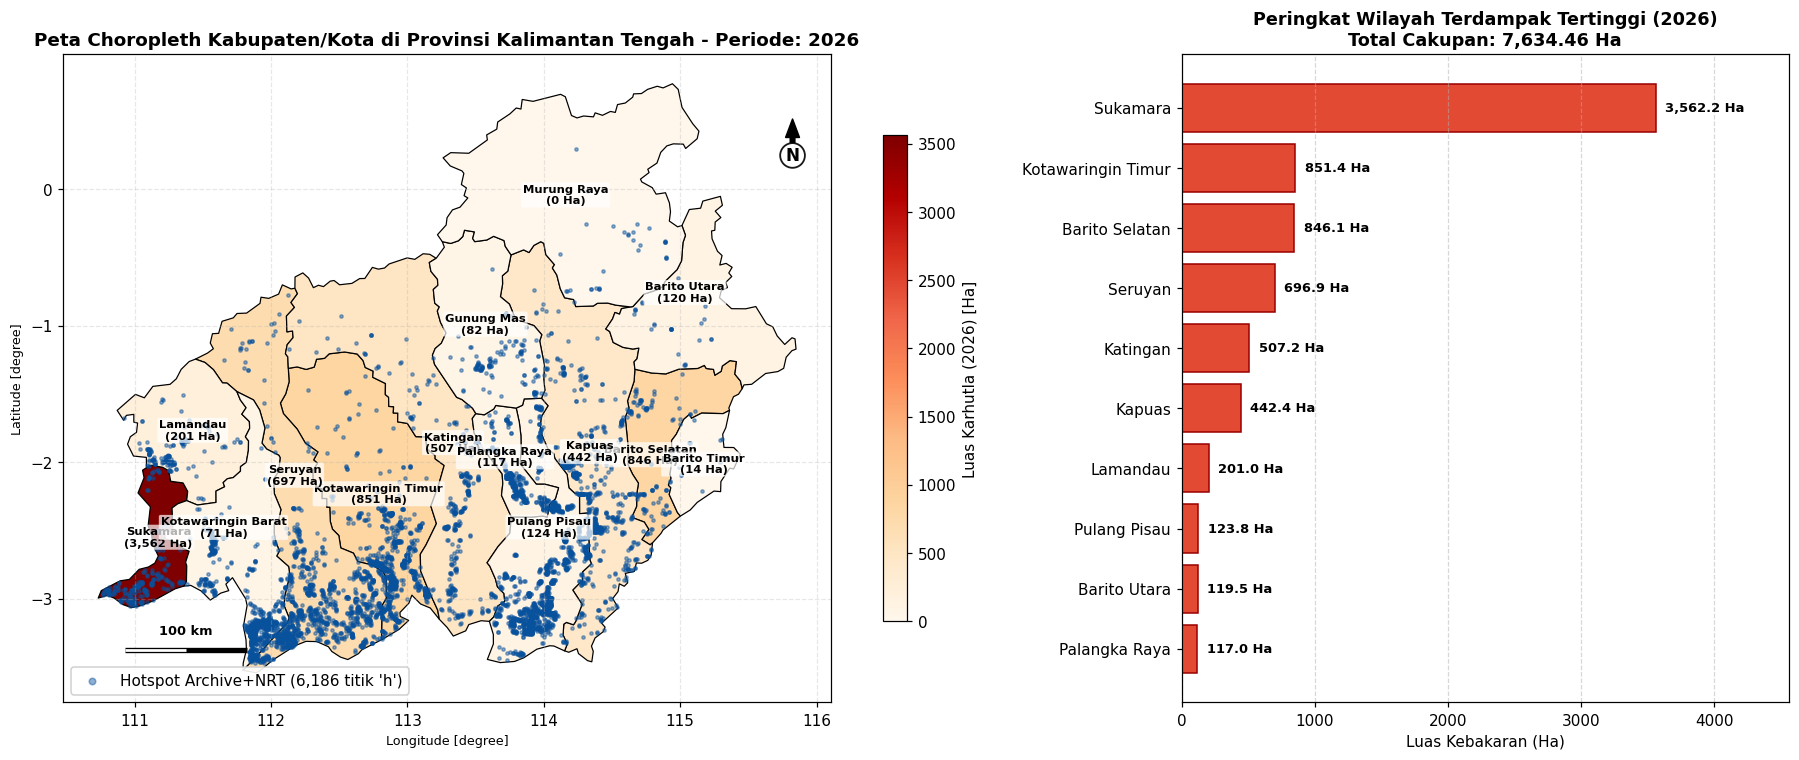

In [18]:
# Contoh pemanggilan manual fungsi pemilih untuk Provinsi lain dan Tahun lain (misal: Kalimantan Tengah Tahun 2026)
tampilkan_peta_karhutla(tahun="2026", provinsi="Kalimantan Tengah", cmap="OrRd", tampilkan_hotspot=True, auto_save=True)